# PP17 — 3D Reconstruction from Stereo Images
### Graded assignment · Research Intake 2026 · Day 36 · Gudsky Research Foundation

**Module:** Computer Vision Fundamentals  |  **File:** `PP17_3DVision.ipynb`  |  **Needs:** a laptop or Colab (CPU is enough)

This notebook is a complete, **measured** worked solution to assignment **PP17** from the Day 36 notes
(*"3D Vision & Video Processing"*, Assignment / Practical Project Brief). It follows the brief and its rubric
section by section. Section numbers such as **§4.1** point back to the Day 36 notes; it is the companion of the lab
notebook `CV_3DVision.ipynb`, but it runs on its own.

---
### The task in one paragraph
Reconstruct depth (and, optionally, a point cloud) from a stereo pair — **Path A**: calibrated, rectified input,
scored against ground truth; **Path B**: a raw pair, where *you* calibrate, estimate the fundamental matrix and
rectify; then **compare** the two quantitatively and **attribute** each error to its source.
The rubric puts 55 % of the grade on Path B and on the comparison, so most of the effort below goes there.

| Rubric component | Weight | Where in this notebook |
|---|---:|---|
| Path A implementation | 25 % | Part 2 (Middlebury, ground truth) and Part 3 (our desk rig, metric depth) |
| Path B implementation | 30 % | Part 4 (own calibration → F by detect-match-RANSAC → rectification → same matcher) |
| Path A vs. Path B comparison, error attribution | 25 % | Part 5 (13 independent test pairs, then controlled experiments that isolate each error source) |
| Code quality & write-up | 20 % | typed, documented functions (Part 1) · written discussion (Part 5.5) · README (Part 7) |

Optional point cloud: Part 6. Submission checklist: Part 7.

---
### Data — nothing here is invented
| Data | Used for | Source |
|---|---|---|
| Middlebury 2003 *Cones* and *Teddy* — rectified pairs with ground-truth disparity | Path A, disparity-space evaluation | `opencv_extra` test data (originally Scharstein & Szeliski, 2003) |
| 13 stereo photo pairs of a 9 × 6 checkerboard, one real two-camera rig | Path A and Path B, **metric** evaluation | OpenCV sample data |

Every number carries a tag: `[measured]` = computed here from real data · `[simulated]` = synthetic ·
`[assumed]` = a value we had to choose because the true one is not published.

### How the evaluation avoids fooling itself
- **Leave-one-pair-out.** To test on pair *k*, **every** calibration quantity (intrinsics, stereo pose) is re-estimated from the
  other 12 pairs. A calibration is never tested on the photos it was fitted to.
- **Reference distance.** The checkerboard in pair *k* has a known geometry (25 mm squares). Its pose from `solvePnP`
  gives the true depth of its 54 corners — independent of the stereo matcher.
  *Limit:* this reference uses the intrinsics $K$, so it tests rectification, pose and matching — **not** $K$ itself.
  $K$ is checked separately against OpenCV's own calibration file (Part 4.1).
- **One matcher for both paths** (OpenCV `StereoSGBM`, identical settings) — so differences between the paths cannot come from the matcher.
- **Honest scoring:** pixels where a method gives no answer are *not* counted as errors, but the **density** is always reported next to the error.

**Running it** — *Colab:* Runtime → Run all.  *Local:* `pip install opencv-python numpy matplotlib scipy`.
Works with OpenCV 4.x and 5.x. First run downloads ≈ 6 MB. Parts are meant to be run in order.

In [1]:
# --- 0.1 Imports, versions, reproducibility ---------------------------------------------------
import shutil
import ssl
import time
import urllib.error
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import Optional, Sequence

import cv2
import matplotlib.pyplot as plt
import numpy as np

SEED = 17  # PP17 → one seed for everything
rng = np.random.default_rng(SEED)
cv2.setRNGSeed(SEED)  # OpenCV's RANSAC draws random samples as well

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "font.size": 9, "axes.titlesize": 10, "image.interpolation": "nearest"})
try:  # store figures as JPEG inside the .ipynb → a much smaller file
    from matplotlib_inline.backend_inline import set_matplotlib_formats

    set_matplotlib_formats("jpeg", pil_kwargs={"quality": 88})
except Exception:  # not in Jupyter → default format, nothing else changes
    pass

print(f"OpenCV {cv2.__version__} | NumPy {np.__version__} | seed {SEED}")
assert hasattr(cv2, "SIFT_create"), "This notebook needs SIFT (OpenCV >= 4.4). Run: pip install -U opencv-python"

OpenCV 4.14.0 | NumPy 2.4.6 | seed 17


In [2]:
# --- 0.2 Download the data (≈ 6 MB, pinned to a release tag so the files can never change) ----
DATA = Path("pp17_data")
OUT = Path("pp17_outputs")
OUT.mkdir(exist_ok=True)

OPENCV_TAG = "4.12.0"
OPENCV_RAW = f"https://raw.githubusercontent.com/opencv/opencv/{OPENCV_TAG}/samples/data"
EXTRA_RAW = f"https://raw.githubusercontent.com/opencv/opencv_extra/{OPENCV_TAG}/testdata/cv/stereomatching/datasets"
PAIR_IDS = ["01", "02", "03", "04", "05", "06", "07", "08", "09", "11", "12", "13", "14"]  # there is no pair 10

FILES = {}  # local path  ->  URL
for i in PAIR_IDS:  # 13 stereo photos of a 9x6 checkerboard
    FILES[f"rig/left{i}.jpg"] = f"{OPENCV_RAW}/left{i}.jpg"
    FILES[f"rig/right{i}.jpg"] = f"{OPENCV_RAW}/right{i}.jpg"
FILES["rig/left_intrinsics.yml"] = f"{OPENCV_RAW}/left_intrinsics.yml"  # OpenCV's own calibration of the left camera
SCENES = ("cones", "teddy")  # Middlebury 2003 stereo pairs + ground truth
for scene in SCENES:
    for name in ("im2.png", "im6.png", "disp2.png", "disp6.png"):
        FILES[f"middlebury/{scene}/{name}"] = f"{EXTRA_RAW}/{scene}/{name}"


def open_url(url: str):
    """urlopen with one fallback: if Python cannot find the system's certificates (typical for python.org
    installers on macOS), try again with the certificate bundle of the `certifi` package."""
    try:
        return urllib.request.urlopen(url, timeout=120)
    except urllib.error.URLError as exc:
        if not isinstance(exc.reason, ssl.SSLCertVerificationError):
            raise
        try:
            import certifi
        except ImportError:
            raise exc from None
        return urllib.request.urlopen(url, timeout=120, context=ssl.create_default_context(cafile=certifi.where()))


def fetch(rel_path: str, url: str, retries: int = 3) -> bool:
    """Download `url` to DATA/rel_path unless it is already there. Returns True on success."""
    dest = DATA / rel_path
    if dest.exists() and dest.stat().st_size > 0:
        return True
    dest.parent.mkdir(parents=True, exist_ok=True)
    error = None
    for attempt in range(retries):
        try:
            tmp = dest.with_name(dest.name + ".part")
            with open_url(url) as response, open(tmp, "wb") as fh:
                shutil.copyfileobj(response, fh)
            tmp.replace(dest)
            return True
        except Exception as exc:  # network hiccup → wait and retry
            error = exc
            time.sleep(1.5 * (attempt + 1))
    print(f"  FAILED  {rel_path}: {error}")
    return False


t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    results_dl = list(pool.map(lambda item: fetch(*item), FILES.items()))
size_mb = sum((DATA / p).stat().st_size for p, ok in zip(FILES, results_dl) if ok) / 1e6
print(f"{sum(results_dl)}/{len(FILES)} files ready in '{DATA}/' ({size_mb:.1f} MB, {time.time() - t0:.1f} s)")
if not all(results_dl):
    print("Some downloads failed. Check the internet connection and re-run this cell (finished files are skipped).")

35/35 files ready in 'pp17_data/' (2.1 MB, 1.5 s)


In [3]:
# --- 0.3 Small helpers -----------------------------------------------------------------------
def imread_rgb(path) -> np.ndarray:
    """Read an image as RGB uint8 (OpenCV loads BGR — matplotlib wants RGB)."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    assert bgr is not None, f"could not read {path} — did the download in cell 0.2 succeed?"
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def imread_gray(path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    assert gray is not None, f"could not read {path} — did the download in cell 0.2 succeed?"
    return gray


def table(rows: Sequence[Sequence], header: Sequence[str]) -> None:
    """Print a small aligned text table (keeps the notebook free of extra dependencies)."""
    cells = [[str(c) for c in header]] + [[f"{c:.4g}" if isinstance(c, float) else str(c) for c in row] for row in rows]
    widths = [max(len(r[i]) for r in cells) for i in range(len(header))]
    for k, row in enumerate(cells):
        print("  ".join(c.ljust(w) for c, w in zip(row, widths)))
        if k == 0:
            print("  ".join("-" * w for w in widths))


def fmt_len(metres: float) -> str:
    """Human-readable length: mm, cm or m."""
    if not np.isfinite(metres):
        return "n/a"
    return (
        f"{metres * 1000:.1f} mm" if metres < 0.01 else (f"{metres * 100:.1f} cm" if metres < 1 else f"{metres:.2f} m")
    )


print("helpers ready: imread_rgb, imread_gray, table, fmt_len")

helpers ready: imread_rgb, imread_gray, table, fmt_len


---
# Part 1 — The pipeline as typed, documented functions  *(§2.4 · §3.3 · §4)*

Everything later in the notebook calls the functions defined in this part, so each pipeline stage exists **once**,
and Path A and Path B differ only in the stages they are *supposed* to differ in.

| Stage | Function | Used by |
|---|---|---|
| 1. Corner detection | `find_corners` | both |
| 2. Intrinsics $K$, distortion (Zhang's method, §2.4) | `calibrate_mono` | both |
| 3a. Stereo pose $R, T$ from many board photos | `stereo_pose` | **Path A** |
| 3b. Detect → match → RANSAC → $F$ → $E$ → $R, \hat t$ → refine | `match_sift`, `estimate_F`, `pose_from_F`, `refine_pose` | **Path B** |
| 4. Rectification (§3.3) | `build_rectification`, `rectify_images` | both |
| 5. Disparity (§4.2) — **identical settings for both paths** | `run_sgbm` | both |
| 6. Disparity → metric depth (§4.1) | `depth_from_disparity` | both |
| 7. Evaluation against a known distance | `board_truth_xyz`, `measure_pair` | both |

**Units.** Baseline in **metres**, focal length and disparity in **pixels** → depth in metres (the §11 units pitfall).

*Needs:* Part 0.

In [4]:
# --- 1.1 Stages 1–2: corner detection and calibration  [measured] ---------------------------------
PATTERN = (9, 6)  # inner corners per row, per column
SQUARE_M = 0.025  # side of one square in METRES (the value used by OpenCV's reference calibration of this rig)

# 3D coordinates of the 54 corners in the board's own frame: (0,0,0), (1,0,0), ... scaled by the square size, Z = 0
BOARD_PTS = np.zeros((PATTERN[0] * PATTERN[1], 3), np.float32)
BOARD_PTS[:, :2] = np.mgrid[0 : PATTERN[0], 0 : PATTERN[1]].T.reshape(-1, 2) * SQUARE_M


def find_corners(gray: np.ndarray) -> Optional[np.ndarray]:
    """Return the 54 checkerboard corners as a (54, 1, 2) float32 array, refined to sub-pixel accuracy."""
    found, corners = cv2.findChessboardCorners(gray, PATTERN)
    if not found:
        return None
    corners = np.asarray(corners, np.float32).reshape(-1, 1, 2)  # same shape on OpenCV 4 and 5
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1e-3)
    return cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria).reshape(-1, 1, 2)


GRAY_L = [imread_gray(DATA / f"rig/left{i}.jpg") for i in PAIR_IDS]
GRAY_R = [imread_gray(DATA / f"rig/right{i}.jpg") for i in PAIR_IDS]
CORN_L = [find_corners(g) for g in GRAY_L]
CORN_R = [find_corners(g) for g in GRAY_R]
assert all(c is not None for c in CORN_L + CORN_R), "a checkerboard was not detected"
IMG_SIZE = GRAY_L[0].shape[::-1]  # (width, height)
N_PAIRS = len(PAIR_IDS)
print(
    f"{N_PAIRS} stereo pairs, image size {IMG_SIZE}, all {2 * N_PAIRS} checkerboards detected ({len(BOARD_PTS)} corners each)"
)


def calibrate_mono(corner_list: Sequence[np.ndarray]):
    """Zhang's method for ONE camera. Returns (rms reprojection error in px, K, distortion coefficients)."""
    rms, K, dist, _, _ = cv2.calibrateCamera([BOARD_PTS] * len(corner_list), list(corner_list), IMG_SIZE, None, None)
    return float(rms), K, dist


def stereo_pose(corn_l: Sequence[np.ndarray], corn_r: Sequence[np.ndarray], K1, d1, K2, d2):
    """Path A pose: rotation R and translation T of the right camera relative to the left (right = R·left + T),
    estimated from the board corners of many photo pairs with the intrinsics held fixed. Returns (rms px, R, T)."""
    out = cv2.stereoCalibrate(
        [BOARD_PTS] * len(corn_l), list(corn_l), list(corn_r), K1, d1, K2, d2, IMG_SIZE, flags=cv2.CALIB_FIX_INTRINSIC
    )
    return float(out[0]), out[5], out[6].ravel()

13 stereo pairs, image size (640, 480), all 26 checkerboards detected (54 corners each)


In [5]:
# --- 1.2 Stage 3b: detect → match → RANSAC → F → E → pose  (the Day 28 pipeline, §3.3)  -----------
SIFT = cv2.SIFT_create(contrastThreshold=0.02)  # a lower threshold than the default keeps more (weaker) keypoints


def match_sift(gray_a: np.ndarray, gray_b: np.ndarray, ratio: float = 0.8):
    """Detect SIFT keypoints, match descriptors, keep matches that pass Lowe's ratio test.
    Returns the matched pixel coordinates as two (N, 2) float32 arrays."""
    kp_a, des_a = SIFT.detectAndCompute(gray_a, None)
    kp_b, des_b = SIFT.detectAndCompute(gray_b, None)
    knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(des_a, des_b, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    return np.float32([kp_a[m.queryIdx].pt for m in good]), np.float32([kp_b[m.trainIdx].pt for m in good])


def undistort_px(points: np.ndarray, K: np.ndarray, dist: np.ndarray) -> np.ndarray:
    """Remove lens distortion from pixel coordinates (the result is still in pixels)."""
    return cv2.undistortPoints(np.asarray(points, np.float32).reshape(-1, 1, 2), K, dist, P=K).reshape(-1, 2)


def estimate_F(p_l: np.ndarray, p_r: np.ndarray, K1, d1, K2, d2, threshold_px: float = 1.0):
    """RANSAC fundamental matrix from matched keypoints. Distortion is removed first, because the epipolar
    constraint is a statement about straight light rays. Returns (F, inlier mask, undistorted left, undistorted right)."""
    u_l, u_r = undistort_px(p_l, K1, d1), undistort_px(p_r, K2, d2)
    F, mask = cv2.findFundamentalMat(u_l, u_r, cv2.FM_RANSAC, threshold_px, 0.999)
    if F is None or F.shape != (3, 3):  # RANSAC found no model (can happen with a handful of matches)
        return None, np.zeros(len(u_l), bool), u_l, u_r
    return F, mask.ravel().astype(bool), u_l, u_r


def normalise(u: np.ndarray, K: np.ndarray) -> np.ndarray:
    """Pixel coordinates → normalised image coordinates (what the camera would see with K = identity)."""
    return (u - [K[0, 2], K[1, 2]]) / [K[0, 0], K[1, 1]]


def pose_from_F(F: np.ndarray, u_l: np.ndarray, u_r: np.ndarray, inliers: np.ndarray, K1, K2):
    """F → essential matrix E = K2ᵀ F K1 (forced to the (s, s, 0) singular-value form) → rotation R and the
    DIRECTION of the translation (unit length). Of the four algebraic solutions recoverPose keeps the one that puts
    the points in front of both cameras. Returns (R, t_unit, number of points in front)."""
    U, S, Vt = np.linalg.svd(K2.T @ F @ K1)
    s = 0.5 * (S[0] + S[1])
    E = U @ np.diag([s, s, 0.0]) @ Vt
    n_good, R, t, _ = cv2.recoverPose(E, normalise(u_l[inliers], K1), normalise(u_r[inliers], K2), np.eye(3))
    return R, t.ravel(), int(n_good)


def skew(t: np.ndarray) -> np.ndarray:
    return np.array([[0, -t[2], t[1]], [t[2], 0, -t[0]], [-t[1], t[0], 0]])


def refine_pose(R0: np.ndarray, t0: np.ndarray, u_l, u_r, K1, K2):
    """Polish (R, t_unit) by minimising the Sampson epipolar error of the inlier matches over the 5 free parameters of an
    essential matrix. F was estimated WITHOUT knowing K (7 parameters); here K is used, so the pose must be a real
    camera motion (5 parameters). The residual is in pixels; a robust loss limits the influence of leftover outliers."""
    from scipy.optimize import least_squares

    n_l, n_r = normalise(u_l, K1), normalise(u_r, K2)
    xl, xr = np.c_[n_l, np.ones(len(n_l))], np.c_[n_r, np.ones(len(n_r))]
    f_px = 0.5 * (K1[0, 0] + K2[0, 0])

    def unpack(p):  # 3 numbers for the rotation (Rodrigues vector), 2 angles for the direction of t
        t = np.array([np.sin(p[3]) * np.cos(p[4]), np.sin(p[3]) * np.sin(p[4]), np.cos(p[3])])
        return cv2.Rodrigues(p[:3])[0], t

    def residuals(p):
        R, t = unpack(p)
        E = skew(t) @ R
        Ex, Etx = xl @ E.T, xr @ E
        sampson = np.sum(xr * Ex, axis=1) / np.sqrt(Ex[:, 0] ** 2 + Ex[:, 1] ** 2 + Etx[:, 0] ** 2 + Etx[:, 1] ** 2)
        return f_px * sampson

    p0 = np.r_[cv2.Rodrigues(R0)[0].ravel(), np.arccos(np.clip(t0[2], -1, 1)), np.arctan2(t0[1], t0[0])]
    return unpack(least_squares(residuals, p0, loss="soft_l1", f_scale=1.0).x)


def estimate_pose_B(p_l: np.ndarray, p_r: np.ndarray, K1, d1, K2, d2, refine: bool = True) -> dict:
    """Path B in one call: matches → F (RANSAC) → E → (R, t_unit) → optional refinement. The metric length of the
    translation is NOT in here — two photos cannot know it (see Part 4.3)."""
    F, inl, u_l, u_r = estimate_F(p_l, p_r, K1, d1, K2, d2)
    if F is None or inl.sum() < 8:
        return {"ok": False, "n_inliers": int(inl.sum())}
    R, t, _ = pose_from_F(F, u_l, u_r, inl, K1, K2)
    if refine:
        R, t = refine_pose(R, t, u_l[inl], u_r[inl], K1, K2)
    return {"ok": True, "F": F, "inliers": inl, "u_l": u_l, "u_r": u_r, "R": R, "t": t, "n_inliers": int(inl.sum())}

In [6]:
# --- 1.3 Stages 4–6: rectification, disparity, depth  ---------------------------------------------
def build_rectification(K1, d1, K2, d2, R: np.ndarray, T: np.ndarray) -> dict:
    """Rotate both virtual cameras until their image rows coincide (§3.3).
    Returns the warping maps and the rectified camera model (focal length in px, baseline in metres)."""
    T_col = np.asarray(T, dtype=np.float64).reshape(3, 1)  # OpenCV 5 is strict: a translation must be a 3x1 column
    R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(
        K1, d1, K2, d2, IMG_SIZE, R, T_col, flags=cv2.CALIB_ZERO_DISPARITY, alpha=0
    )
    return {
        "K1": K1, "d1": d1, "K2": K2, "d2": d2,
        "R1": R1, "R2": R2, "P1": P1, "P2": P2, "Q": Q,
        "map_l": cv2.initUndistortRectifyMap(K1, d1, R1, P1, IMG_SIZE, cv2.CV_32FC1),
        "map_r": cv2.initUndistortRectifyMap(K2, d2, R2, P2, IMG_SIZE, cv2.CV_32FC1),
        "f": float(P1[0, 0]),
        "baseline": float(-P2[0, 3] / P2[0, 0]),
    }


def rectify_images(rect: dict, gray_l: np.ndarray, gray_r: np.ndarray):
    return (
        cv2.remap(gray_l, rect["map_l"][0], rect["map_l"][1], cv2.INTER_LINEAR),
        cv2.remap(gray_r, rect["map_r"][0], rect["map_r"][1], cv2.INTER_LINEAR),
    )


def rectified_points(rect: dict, pts_l: np.ndarray, pts_r: np.ndarray):
    """Where raw pixel coordinates land in the rectified left / right images."""
    c_l = cv2.undistortPoints(np.reshape(pts_l, (-1, 1, 2)), rect["K1"], rect["d1"], R=rect["R1"], P=rect["P1"])
    c_r = cv2.undistortPoints(np.reshape(pts_r, (-1, 1, 2)), rect["K2"], rect["d2"], R=rect["R2"], P=rect["P2"])
    return c_l.reshape(-1, 2), c_r.reshape(-1, 2)


def run_sgbm(left: np.ndarray, right: np.ndarray, num_disp: int, block: int = 5) -> np.ndarray:
    """Semi-Global Block Matching with fixed settings. Returns disparity in pixels (float32); negative = 'no confident match'."""
    channels = 1 if left.ndim == 2 else 3
    matcher = cv2.StereoSGBM_create(
        minDisparity=0,
        numDisparities=num_disp,
        blockSize=block,
        P1=8 * channels * block**2,
        P2=32 * channels * block**2,  # smoothness penalties
        disp12MaxDiff=1,
        uniquenessRatio=10,
        speckleWindowSize=100,
        speckleRange=2,
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
    )
    return matcher.compute(left, right).astype(np.float32) / 16.0  # OpenCV returns fixed-point values x16


def depth_from_disparity(disparity_px, focal_px: float, baseline_m: float):
    """Z = f · B / d.  Units: pixels · metres / pixels = metres  (§4.1)."""
    return focal_px * baseline_m / disparity_px

In [7]:
# --- 1.4 Stage 7: evaluation against a known distance  [measured] ---------------------------------
def leave_one_out(k: int, subset: Optional[Sequence[int]] = None) -> dict:
    """Everything that is estimated from checkerboard photos, re-estimated WITHOUT pair k:
    intrinsics of both cameras and the stereo pose (Path A's calibration). `subset` restricts the photos used."""
    use = [j for j in (range(N_PAIRS) if subset is None else subset) if j != k]
    rms1, K1, d1 = calibrate_mono([CORN_L[j] for j in use])
    rms2, K2, d2 = calibrate_mono([CORN_R[j] for j in use])
    rms_s, R, T = stereo_pose([CORN_L[j] for j in use], [CORN_R[j] for j in use], K1, d1, K2, d2)
    return {"K1": K1, "d1": d1, "K2": K2, "d2": d2, "R": R, "T": T, "baseline": float(np.linalg.norm(T)),
            "rms": (rms1, rms2, rms_s), "used": use}


def board_truth_xyz(rect: dict, k: int, K_gt: np.ndarray, d_gt: np.ndarray) -> np.ndarray:
    """TRUE 3D positions (3 x 54, metres) of the board corners of pair k in the RECTIFIED left camera frame. The board's pose
    comes from solvePnP (a method that never looks at the right image), with K_gt estimated WITHOUT this pair."""
    _, rvec, tvec = cv2.solvePnP(BOARD_PTS, CORN_L[k], K_gt, d_gt)
    corners_cam = cv2.Rodrigues(rvec)[0] @ BOARD_PTS.T + tvec.reshape(3, 1)  # corners in the left camera frame (m)
    return rect["R1"] @ corners_cam


def measure_pair(rect: dict, k: int, K_gt, d_gt, num_disp: int, keep_maps: bool = False, matcher=run_sgbm) -> dict:
    """Rectify pair k with `rect`, run the matcher, and compare with the board's true depth.
    Returns per-corner arrays: true depth, estimated depth, rectification row error (px), disparity at the corners."""
    rl, rr = rectify_images(rect, GRAY_L[k], GRAY_R[k])
    disp = matcher(rl, rr, num_disp)
    c_l, c_r = rectified_points(rect, CORN_L[k], CORN_R[k])  # where the 54 corners are in the rectified images
    u, v = np.round(c_l).astype(int).T
    inside = (u >= 0) & (u < disp.shape[1]) & (v >= 0) & (v < disp.shape[0])
    d_at = np.full(len(u), np.nan)
    d_at[inside] = disp[v[inside], u[inside]]
    d_at[d_at <= 0] = np.nan  # unmatched → no depth, not "depth 0"
    xyz_ref = board_truth_xyz(rect, k, K_gt, d_gt)
    z_ref = xyz_ref[2]  # depth along the rectified camera axis
    z_est = depth_from_disparity(d_at, rect["f"], rect["baseline"])
    out = {
        "z_ref": z_ref, "z_est": z_est, "d_at": d_at, "xyz_ref": xyz_ref, "uv": c_l,
        "d_geo": c_l[:, 0] - c_r[:, 0],  # the disparity the corners SHOULD have given this rectification
        "row_err": np.abs(c_l[:, 1] - c_r[:, 1]),
        "matched": int(np.sum(~np.isnan(d_at))),
    }
    if keep_maps:
        out.update(left=rl, right=rr, disp=disp)
    return out


def summarise(m: dict) -> dict:
    """One-number summaries of a `measure_pair` result (NaN when fewer than 10 corners could be matched)."""
    err = 1000 * np.abs(m["z_est"] - m["z_ref"])  # millimetres
    ok = m["matched"] >= 10
    return {
        "matched": m["matched"],
        "median_mm": float(np.nanmedian(err)) if ok else np.nan,
        "median_pct": float(100 * np.nanmedian(err / (1000 * m["z_ref"]))) if ok else np.nan,
        "row_px": float(np.mean(m["row_err"])),
        "z_mean": float(np.mean(m["z_ref"])),
    }


print("pipeline functions ready")

pipeline functions ready


---
# Part 2 — Path A on a benchmark: disparity and depth, scored against ground truth  *(§4 · rubric 25 %)*

**Path A, as the brief defines it:** intrinsics, extrinsics and a **rectified** pair are *given*. Only one skill is tested:
stereo matching → disparity → depth → honest evaluation. We use two Middlebury 2003 scenes (*Cones*, *Teddy*): rectified pairs with
ground-truth disparity from structured light (stored × 4, quarter-pixel accuracy, `0` = unknown).

**What we implement.** (1) a block matcher written from scratch — a sum-of-absolute-differences **cost volume** with
winner-takes-all (§4.2) — at three window sizes, and (2) OpenCV's `StereoBM` and `StereoSGBM`.
**Metrics** (the brief suggests mean/median disparity error): mean and median absolute error in pixels, the share of
pixels off by more than 1 px, and — always next to them — the **density** (share of pixels the method answered).
Errors are reported separately for pixels both cameras see and for *occluded* pixels (visible in the left image only),
found by cross-checking the left and right ground-truth maps — occlusions are a property of the scene, not a bug (§5.1).

*Needs:* Parts 0–1.

In [8]:
# --- 2.1 Load the benchmark pairs and their ground truth  [measured] ------------------------------
def load_middlebury(scene: str):
    """Returns (left RGB, right RGB, left ground-truth disparity in px, right ground truth). 0 = unknown."""
    folder = DATA / "middlebury" / scene
    gt_l = imread_gray(folder / "disp2.png").astype(np.float32) / 4.0  # stored x4 (quarter-pixel accuracy)
    gt_r = imread_gray(folder / "disp6.png").astype(np.float32) / 4.0
    return imread_rgb(folder / "im2.png"), imread_rgb(folder / "im6.png"), gt_l, gt_r


def occlusion_mask(gt_left: np.ndarray, gt_right: np.ndarray, tol: float = 1.0) -> np.ndarray:
    """True where a left pixel is NOT visible in the right image, found by cross-checking the two ground-truth maps."""
    h, w = gt_left.shape
    ys, xs = np.mgrid[0:h, 0:w]
    x_right = np.round(xs - gt_left).astype(int)
    inside = (x_right >= 0) & (gt_left > 0)
    back = np.zeros_like(gt_left)
    back[inside] = gt_right[ys[inside], x_right[inside]]
    return (gt_left > 0) & (~inside | (np.abs(back - gt_left) > tol))


def score(disp: np.ndarray, valid: np.ndarray, gt: np.ndarray, region: np.ndarray) -> dict:
    """Compare a disparity map with ground truth inside `region`, ONLY where the method gave an answer (`valid`)."""
    use = region & valid
    err = np.abs(disp[use] - gt[use])
    return {
        "density": 100 * use.sum() / region.sum(),
        "mean": float(err.mean()),
        "median": float(np.median(err)),
        "bad1": 100 * float(np.mean(err > 1.0)),
    }


MAX_DISP = 64  # search range in px; must exceed the largest true disparity (checked below)
SCENE_DATA = {}
rows = []
for scene in SCENES:
    left, right, gt, gt_r = load_middlebury(scene)
    known = gt > 0
    occ = occlusion_mask(gt, gt_r)
    SCENE_DATA[scene] = {"left": left, "right": right, "gt": gt, "known": known, "occ": occ, "vis": known & ~occ,
                         "gl": cv2.cvtColor(left, cv2.COLOR_RGB2GRAY), "gr": cv2.cvtColor(right, cv2.COLOR_RGB2GRAY)}
    assert gt.max() < MAX_DISP, f"{scene}: ground truth exceeds the search range"
    rows.append((scene, f"{left.shape[1]}x{left.shape[0]}", f"{gt[known].min():.1f}-{gt[known].max():.1f} px",
                 f"{known.mean():.1%}", f"{occ.sum() / known.sum():.1%}"))
table(rows, ["scene", "size", "true disparity", "pixels with ground truth", "of those: occluded"])

scene  size     true disparity  pixels with ground truth  of those: occluded
-----  -------  --------------  ------------------------  ------------------
cones  450x375  5.5-55.0 px     96.8%                     12.1%             
teddy  450x375  12.5-52.8 px    98.0%                     10.9%             



CONES  (errors in pixels, against ground truth)
method                      density  mean err  median err  bad > 1 px  bad (visible)  bad (occluded)
--------------------------  -------  --------  ----------  ----------  -------------  --------------
ours: block matching 3x3    100 %    6.675     1           49.2 %      42.8 %         95.4 %        
ours: block matching 9x9    100 %    3.655     0.5         27.9 %      18.8 %         93.7 %        
ours: block matching 21x21  100 %    3.097     0.25        24.4 %      15.1 %         91.9 %        
OpenCV StereoBM 15x15       73 %     0.6192    0.125       6.0 %       3.9 %          74.3 %        
OpenCV StereoSGBM 5x5       83 %     0.6453    0.1875      6.6 %       3.8 %          78.6 %        

TEDDY  (errors in pixels, against ground truth)
method                      density  mean err  median err  bad > 1 px  bad (visible)  bad (occluded)
--------------------------  -------  --------  ----------  ----------  -------------  --------

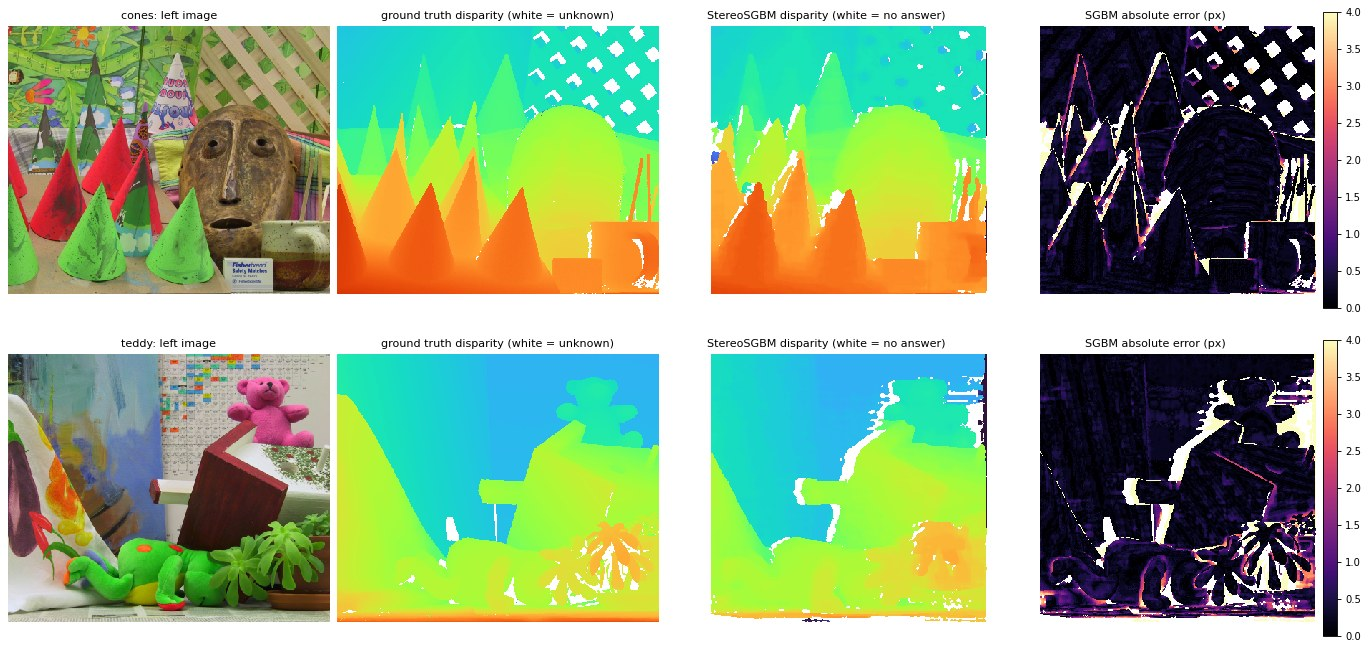

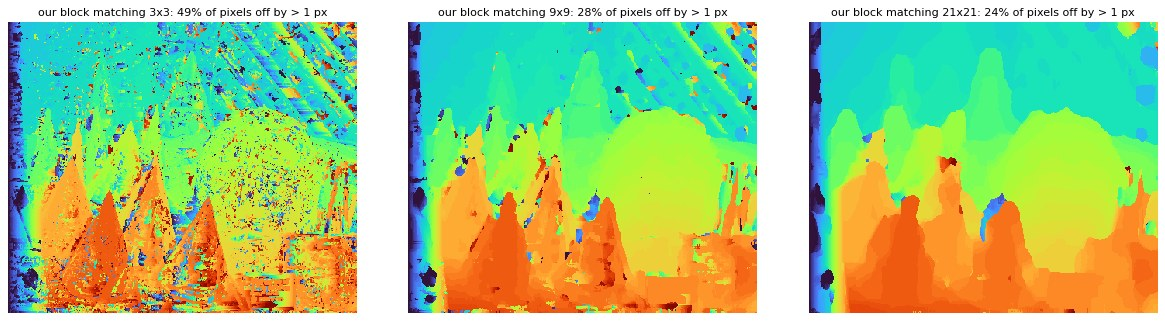

In [9]:
# --- 2.2 Our block matcher (cost volume) vs OpenCV StereoBM and StereoSGBM  [measured] --------------
def sad_cost_volume(left: np.ndarray, right: np.ndarray, max_disp: int, block: int) -> np.ndarray:
    """cost[y, x, d] = mean |left window at (y, x)  -  right window at (y, x - d)|.  Lower = more similar."""
    h, w = left.shape
    L, R = left.astype(np.float32), right.astype(np.float32)
    cost = np.full((h, w, max_disp), np.inf, np.float32)
    for d in range(max_disp):
        diff = np.abs(L[:, d:] - R[:, : w - d])  # compare every pixel with the one d to its left
        cost[:, d:, d] = cv2.blur(diff, (block, block))  # averaging over the window = block matching
    return cost


def scratch_matcher(gray_l: np.ndarray, gray_r: np.ndarray, max_disp: int, block: int = 9) -> np.ndarray:
    """Block matching from scratch: cost volume, then 'winner takes all' = the cheapest shift per pixel."""
    return sad_cost_volume(gray_l, gray_r, max_disp, block).argmin(axis=2).astype(np.float32)


METHODS_A = {}  # scene -> method name -> (disparity map, validity mask)
t_run = {}
for scene, S in SCENE_DATA.items():
    methods = {}
    t0 = time.time()
    for block in (3, 9, 21):
        methods[f"ours: block matching {block}x{block}"] = (
            scratch_matcher(S["gl"], S["gr"], MAX_DISP, block),
            np.ones_like(S["known"]),
        )
    t_run[(scene, "ours")] = (time.time() - t0) / 3
    t0 = time.time()
    bm = cv2.StereoBM_create(numDisparities=MAX_DISP, blockSize=15).compute(S["gl"], S["gr"]).astype(np.float32) / 16.0
    t_run[(scene, "BM")] = time.time() - t0
    methods["OpenCV StereoBM 15x15"] = (bm, bm >= 0)
    t0 = time.time()
    sg = run_sgbm(S["left"], S["right"], MAX_DISP)
    t_run[(scene, "SGBM")] = time.time() - t0
    methods["OpenCV StereoSGBM 5x5"] = (sg, sg >= 0)
    METHODS_A[scene] = methods

SCORES_A = {}
for scene, S in SCENE_DATA.items():
    rows = []
    for name, (disp, valid) in METHODS_A[scene].items():
        s_all, s_vis, s_occ = (score(disp, valid, S["gt"], r) for r in (S["known"], S["vis"], S["occ"]))
        SCORES_A[(scene, name)] = s_all | {
            "bad1_vis": s_vis["bad1"],
            "bad1_occ": s_occ["bad1"],
            "median_vis": s_vis["median"],
        }
        rows.append((name, f"{s_all['density']:.0f} %", s_all["mean"], s_all["median"], f"{s_all['bad1']:.1f} %",
                     f"{s_vis['bad1']:.1f} %", f"{s_occ['bad1']:.1f} %"))
    print(f"\n{scene.upper()}  (errors in pixels, against ground truth)")
    table(rows, ["method", "density", "mean err", "median err", "bad > 1 px", "bad (visible)", "bad (occluded)"])
print(
    "\nruntime per scene (ms): "
    + ", ".join(
        f"{scene}: ours {1000 * t_run[(scene, 'ours')]:.0f}, BM {1000 * t_run[(scene, 'BM')]:.0f}, SGBM {1000 * t_run[(scene, 'SGBM')]:.0f}"
        for scene in SCENES
    )
)

# The unfair way to score: treat "no answer" as the answer 0 and count it as an error
sg_c = METHODS_A["cones"]["OpenCV StereoSGBM 5x5"][0]
naive = np.abs(
    np.where(sg_c >= 0, sg_c, 0)[SCENE_DATA["cones"]["known"]] - SCENE_DATA["cones"]["gt"][SCENE_DATA["cones"]["known"]]
).mean()
print(
    f"\n⚠️ Cones, SGBM: scoring unmatched pixels as disparity 0 would give a mean error of {naive:.2f} px — "
    f"against {SCORES_A[('cones', 'OpenCV StereoSGBM 5x5')]['mean']:.2f} px on the pixels it actually answered."
)

fig, axes = plt.subplots(2, 4, figsize=(17, 8.2), constrained_layout=True)
for row, (scene, S) in zip(axes, SCENE_DATA.items()):
    sg = METHODS_A[scene]["OpenCV StereoSGBM 5x5"][0]
    err = np.where((sg >= 0) & S["known"], np.abs(sg - S["gt"]), np.nan)
    row[0].imshow(S["left"])
    row[0].set_title(f"{scene}: left image")
    row[1].imshow(np.where(S["known"], S["gt"], np.nan), cmap="turbo", vmin=0, vmax=MAX_DISP)
    row[1].set_title("ground truth disparity (white = unknown)")
    row[2].imshow(np.where(sg >= 0, sg, np.nan), cmap="turbo", vmin=0, vmax=MAX_DISP)
    row[2].set_title("StereoSGBM disparity (white = no answer)")
    handle = row[3].imshow(err, cmap="magma", vmin=0, vmax=4)
    row[3].set_title("SGBM absolute error (px)")
    fig.colorbar(handle, ax=row[3], fraction=0.046, pad=0.02)
    for ax in row:
        ax.axis("off")
plt.show()

cones = SCENE_DATA["cones"]
show_blocks = [(b, METHODS_A["cones"][f"ours: block matching {b}x{b}"][0]) for b in (3, 9, 21)]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), constrained_layout=True)
for ax, (b, disp) in zip(axes, show_blocks):
    bad = np.mean(np.abs(disp - cones["gt"])[cones["known"]] > 1.0)
    ax.imshow(disp, cmap="turbo", vmin=0, vmax=MAX_DISP)
    ax.set_title(f"our block matching {b}x{b}: {bad:.0%} of pixels off by > 1 px")
    ax.axis("off")
plt.show()

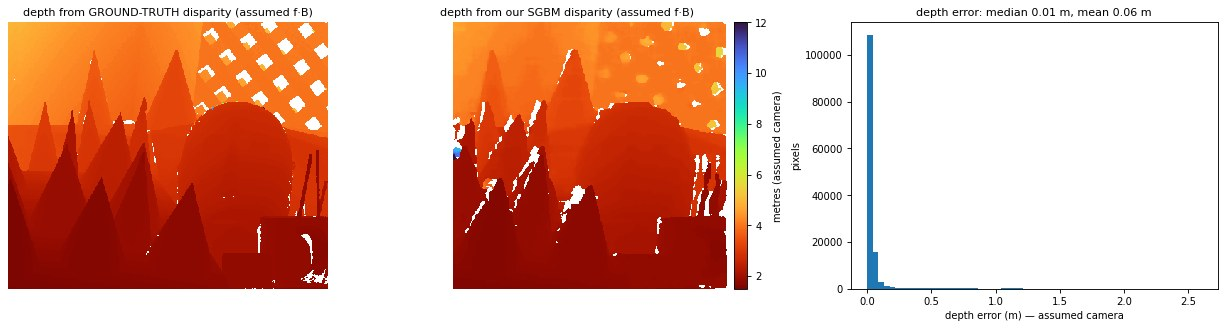

[assumed] f = 700 px, B = 0.12 m. Only the SCALE of the depth map depends on this assumption;
the disparity errors of Part 2.2 do not. A depth error is the disparity error amplified by Z²/(f·B):
depth (assumed camera)  error from the measured median disparity error of 0.19 px
----------------------  ---------------------------------------------------------
1 m                     2.2 mm                                                   
3 m                     2.0 cm                                                   
6 m                     8.0 cm                                                   
10 m                    22.3 cm                                                  


In [10]:
# --- 2.3 Depth map: Z = f·B / d, and what the benchmark does NOT tell us  [assumed camera] ----------
# The true focal length and baseline of the Middlebury 2003 rig are not part of the files we use. The EVALUATION above is therefore
# done in disparity space, where ground truth exists. To draw a depth map anyway we ASSUME a camera: the lecture rig of §4.1.
ASSUMED_F_PX, ASSUMED_B_M = 700.0, 0.12  # [assumed]  → f·B = 84 px·m

sg_c = METHODS_A["cones"]["OpenCV StereoSGBM 5x5"][0]
depth_cones = np.where(sg_c > 0, depth_from_disparity(np.maximum(sg_c, 1e-6), ASSUMED_F_PX, ASSUMED_B_M), np.nan)
depth_gt = np.where(
    cones["known"], depth_from_disparity(np.maximum(cones["gt"], 1e-6), ASSUMED_F_PX, ASSUMED_B_M), np.nan
)
both = np.isfinite(depth_cones) & np.isfinite(depth_gt)
z_err = np.abs(depth_cones - depth_gt)[both]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.0), constrained_layout=True)
for ax, img, title in ((axes[0], depth_gt, "depth from GROUND-TRUTH disparity (assumed f·B)"),
                       (axes[1], depth_cones, "depth from our SGBM disparity (assumed f·B)")):
    handle = ax.imshow(img, cmap="turbo_r", vmin=1.5, vmax=12)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(handle, ax=axes[1], fraction=0.046, pad=0.02, label="metres (assumed camera)")
axes[2].hist(z_err[z_err < 3], bins=60, color="tab:blue")
axes[2].set_xlabel("depth error (m) — assumed camera")
axes[2].set_ylabel("pixels")
axes[2].set_title(f"depth error: median {np.median(z_err):.2f} m, mean {z_err.mean():.2f} m")
plt.show()

print(
    f"[assumed] f = {ASSUMED_F_PX:.0f} px, B = {ASSUMED_B_M} m. Only the SCALE of the depth map depends on this assumption;"
)
print("the disparity errors of Part 2.2 do not. A depth error is the disparity error amplified by Z²/(f·B):")
med_err_px = SCORES_A[("cones", "OpenCV StereoSGBM 5x5")]["median_vis"]
table(
    [(f"{z:g} m", fmt_len(z * z / (ASSUMED_F_PX * ASSUMED_B_M) * med_err_px)) for z in (1.0, 3.0, 6.0, 10.0)],
    ["depth (assumed camera)", f"error from the measured median disparity error of {med_err_px:.2f} px"],
)

In [11]:
# --- 2.4 Failure is partly a property of the scene: textureless regions  [measured] -----------------
def texture_strength(gray: np.ndarray, window: int = 9) -> np.ndarray:
    """Local mean gradient magnitude (grey levels per pixel): ≈ 0 in flat, uniformly coloured regions, large at edges and texture."""
    g = gray.astype(np.float32)
    mag = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3))
    return cv2.blur(mag, (window, window))


def near_depth_jump(gt: np.ndarray, known: np.ndarray, jump_px: float = 1.0, grow: int = 9) -> np.ndarray:
    """Pixels within a few pixels of a jump in the ground-truth disparity (object borders). Errors there come from
    occlusion and edge fattening, NOT from missing texture, so they would confound a texture analysis."""
    g = np.where(known, gt, 0).astype(np.float32)
    jump = (np.abs(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=1)) > jump_px) | (
        np.abs(cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=1)) > jump_px
    )
    return cv2.dilate(jump.astype(np.uint8), np.ones((grow, grow), np.uint8)).astype(bool)


TEXTURE_BINS = ((0, 4, "< 4  (almost flat)"), (4, 8, "4 - 8"), (8, 16, "8 - 16"), (16, 1e9, ">= 16  (textured)"))
TEXTURE_METHODS = ("ours: block matching 9x9", "OpenCV StereoBM 15x15", "OpenCV StereoSGBM 5x5")
rows = []
for scene, S in SCENE_DATA.items():
    tex = texture_strength(S["gl"])
    region = S["vis"] & ~near_depth_jump(S["gt"], S["known"])  # visible to both cameras AND away from object borders
    for lo, hi, label in TEXTURE_BINS:
        reg = region & (tex >= lo) & (tex < hi)
        if reg.sum() < 500:  # too few pixels for a meaningful percentage
            rows.append((scene, label, int(reg.sum()), "-", "-", "-", "-", "-", "-"))
            continue
        cells = []
        for name in TEXTURE_METHODS:
            s = score(*METHODS_A[scene][name], S["gt"], reg)
            cells += [f"{s['density']:.0f} %", f"{s['bad1']:.1f} %"]
        rows.append((scene, label, int(reg.sum()), *cells))
print(
    "Only pixels visible to both cameras and away from depth jumps. Texture = local mean gradient (grey levels / px)."
)
table(
    rows,
    [
        "scene",
        "texture",
        "pixels",
        "ours: density",
        "ours: bad>1px",
        "BM: density",
        "BM: bad>1px",
        "SGBM: density",
        "SGBM: bad>1px",
    ],
)

Only pixels visible to both cameras and away from depth jumps. Texture = local mean gradient (grey levels / px).
scene  texture             pixels  ours: density  ours: bad>1px  BM: density  BM: bad>1px  SGBM: density  SGBM: bad>1px
-----  ------------------  ------  -------------  -------------  -----------  -----------  -------------  -------------
cones  < 4  (almost flat)  32      -              -              -            -            -              -            
cones  4 - 8               987     100 %          65.3 %         76 %         1.1 %        88 %           0.0 %        
cones  8 - 16              9435    100 %          51.0 %         74 %         0.8 %        86 %           0.9 %        
cones  >= 16  (textured)   87633   100 %          8.9 %          84 %         0.4 %        90 %           0.4 %        
teddy  < 4  (almost flat)  2836    100 %          98.4 %         19 %         43.8 %       57 %           61.8 %       
teddy  4 - 8               8654    100 %       

**Read the result (Path A, benchmark).**
- The from-scratch matcher **answers every pixel and is wrong on many of them**; `StereoBM`/`StereoSGBM` **decline** where they are unsure
  and are far more accurate on what they keep. That is why *density and error are always reported together* — an error on its own is meaningless.
- Window size is a trade-off (3 × 3 noisy, 21 × 21 smooth but with fattened object edges) — no window is right everywhere.
- On pixels visible to only one camera (occlusions) every method is wrong most of the time: there is nothing to match.
  This is why the visible/occluded split matters, and why a depth map has holes next to foreground objects.
- Scoring "no answer" as disparity 0 would inflate the SGBM error several-fold and punish honesty.
- **Textureless regions are a property of the scene** (the brief's tip): where the image is almost flat, a pure window matcher is mostly wrong, `StereoBM` mostly declines
  to answer (low density), and `StereoSGBM` still gives answers because its smoothness rule fills the flat patch from its textured surroundings (see the table in 2.4).
  *Method note:* a first attempt that simply split pixels into texture quartiles showed the **most** textured quarter as the worst — because
  object borders are both high-gradient and the place of occlusion errors. Excluding pixels near depth jumps removed that confound.
- **Depth.** The benchmark tells us disparity errors in *pixels*. Converting to metres needs $f$ and $B$, which the benchmark files do not give — we assumed them
  and said so. Part 3 repeats Path A on a rig whose $f$ and $B$ we measured, where depth can be checked against a real distance.

---
# Part 3 — Path A on a real stereo rig: disparity → depth in **metres**, checked against a real distance  *(§2.2 · §3.3 · §4.1)*

Part 2 scored disparity, because that is what the benchmark can tell us. Here every number is **measured**, so disparity can
be turned into real metres and compared with a distance we know.

**Path A setup on the desk rig.** The rig was calibrated in a session of 13 photo pairs (a person holds a 9 × 6 checkerboard
in different poses). *Path A treats that calibration as given*: intrinsics $K, $ distortion, and the stereo pose $R, T$ from `stereoCalibrate`.
To keep the test honest, the calibration given to Path A for pair *k* is computed **without pair *k*** (leave-one-pair-out, Part 1.4).

**The reference.** The board's own geometry (25 mm squares) fixes its distance via `solvePnP` — independently of the stereo matcher.

*Needs:* Parts 0–1.

Calibration given to Path A (12 pairs, WITHOUT pair 01):
  RMS reprojection error: left 0.422 px, right 0.459 px, stereo 0.454 px
  rectified camera: f = 520.4 px, baseline = 8.37 cm

Pair 01: the board is 0.383 m away (solvePnP).  SGBM answered at 52/54 corners.
  median depth error 0.54 mm = 0.15 % of the distance,  rectification row error 0.17 px


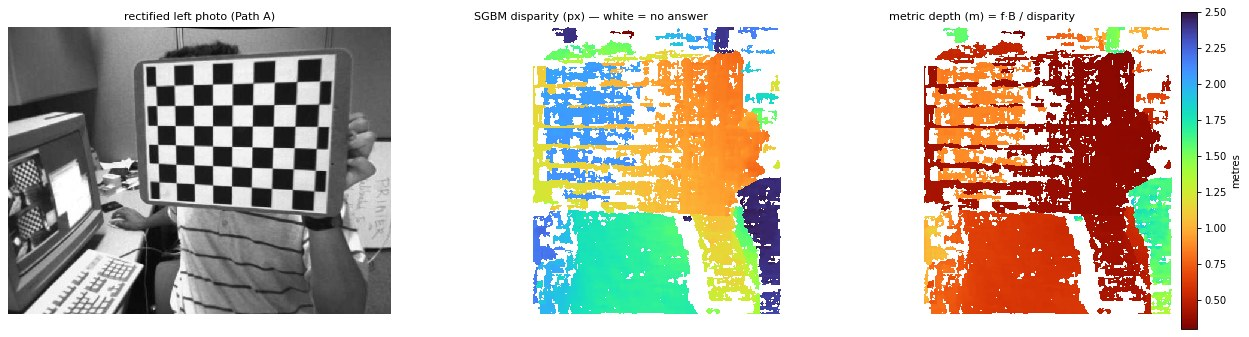

In [12]:
# --- 3.1 Pair 01 as the working example: calibration given to Path A, rectification, disparity, depth  [measured] ---
FOCUS = 0  # pair 01 — the first pair, chosen before looking at any result. Part 5 shows ALL 13 pairs, so you can see how typical it is.
NUM_DISP_RIG = 224  # the board is 0.2–0.45 m away → true disparities up to ≈ 205 px (f·B/Z), so the search range must be that large
MIN_MATCHED = 10  # a pair counts as "failed" if fewer than this many of the 54 board corners received a disparity …
GROSS_ERR_PCT = 20.0  # … or if the median depth error exceeds this many percent: a result that far off is not 'inaccurate', it is wrong

CAL = leave_one_out(FOCUS)
K1, d1, K2, d2 = CAL["K1"], CAL["d1"], CAL["K2"], CAL["d2"]
RECT_A = build_rectification(K1, d1, K2, d2, CAL["R"], CAL["T"])
M_A = measure_pair(RECT_A, FOCUS, K1, d1, NUM_DISP_RIG, keep_maps=True)
S_A = summarise(M_A)

print(f"Calibration given to Path A (12 pairs, WITHOUT pair {PAIR_IDS[FOCUS]}):")
print(
    f"  RMS reprojection error: left {CAL['rms'][0]:.3f} px, right {CAL['rms'][1]:.3f} px, stereo {CAL['rms'][2]:.3f} px"
)
print(f"  rectified camera: f = {RECT_A['f']:.1f} px, baseline = {RECT_A['baseline'] * 100:.2f} cm")
print(
    f"\nPair {PAIR_IDS[FOCUS]}: the board is {S_A['z_mean']:.3f} m away (solvePnP).  SGBM answered at {S_A['matched']}/54 corners."
)
print(
    f"  median depth error {S_A['median_mm']:.2f} mm = {S_A['median_pct']:.2f} % of the distance,  "
    f"rectification row error {S_A['row_px']:.2f} px"
)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.1), constrained_layout=True)
axes[0].imshow(M_A["left"], cmap="gray")
axes[0].set_title("rectified left photo (Path A)")
axes[1].imshow(np.where(M_A["disp"] > 0, M_A["disp"], np.nan), cmap="turbo")
axes[1].set_title("SGBM disparity (px) — white = no answer")
depth_map_A = np.where(
    M_A["disp"] > 0, depth_from_disparity(np.maximum(M_A["disp"], 1e-6), RECT_A["f"], RECT_A["baseline"]), np.nan
)
handle = axes[2].imshow(depth_map_A, cmap="turbo_r", vmin=0.3, vmax=2.5)
axes[2].set_title("metric depth (m) = f·B / disparity")
fig.colorbar(handle, ax=axes[2], fraction=0.046, pad=0.02, label="metres")
for ax in axes:
    ax.axis("off")
plt.show()

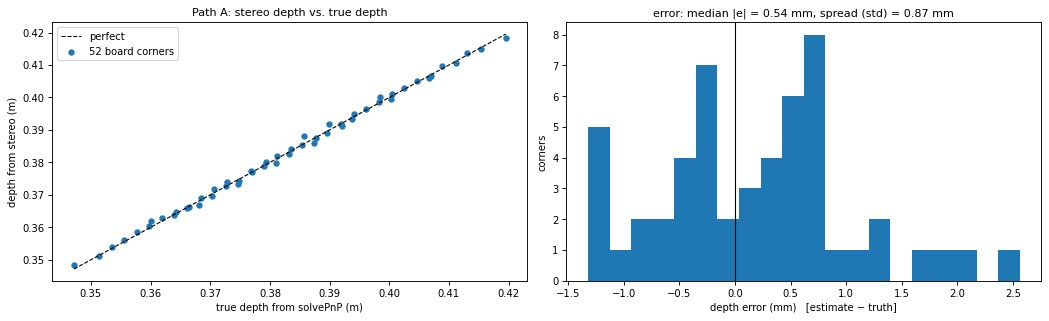

In [13]:
# --- 3.2 The metric check: our depth vs. the board's true depth, corner by corner  [measured] -------
err_mm = 1000 * (M_A["z_est"] - M_A["z_ref"])
ok = ~np.isnan(err_mm)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), constrained_layout=True)
axes[0].plot(
    [M_A["z_ref"].min(), M_A["z_ref"].max()], [M_A["z_ref"].min(), M_A["z_ref"].max()], "k--", lw=1, label="perfect"
)
axes[0].scatter(M_A["z_ref"][ok], M_A["z_est"][ok], s=22, color="tab:blue", label=f"{ok.sum()} board corners")
axes[0].set_xlabel("true depth from solvePnP (m)")
axes[0].set_ylabel("depth from stereo (m)")
axes[0].set_title("Path A: stereo depth vs. true depth")
axes[0].legend()
axes[1].hist(err_mm[ok], bins=20, color="tab:blue")
axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("depth error (mm)   [estimate − truth]")
axes[1].set_ylabel("corners")
axes[1].set_title(
    f"error: median |e| = {np.nanmedian(np.abs(err_mm)):.2f} mm, spread (std) = {np.nanstd(err_mm):.2f} mm"
)
plt.show()

**Read the result (Path A, desk rig).** With the calibration given, stereo depth agrees with the board's true distance to about a millimetre
(≈ 0.2 % at 0.4 m) — and that is on a pair that was **not** used to build the calibration. This is the *floor* of the error:
whatever Path B adds on top of it comes from calibration and rectification, not from the matcher. Part 5 repeats this for all 13 pairs.

⚠️ **Limit.** The reference distance uses the same intrinsics $K$ as the stereo pipeline, so it does not test $K$ itself.
Part 4.1 checks $K$ against OpenCV's own calibration file and Part 5.4 measures how $K$ errors would propagate.

---
# Part 4 — Path B: from a raw pair to depth — calibrate, estimate F, rectify  *(§2.4 · §3.3 · Day 28 · rubric 30 %)*

**Path B, as the brief defines it.** Given only a raw, **unrectified** pair and checkerboard photos from the same camera:
1. **calibrate** the cameras yourself with the checkerboard (intrinsics $K$ and distortion),
2. estimate the **fundamental matrix** $F$ from matched keypoints with the Day 28 *detect → match → RANSAC* pipeline,
3. **rectify** the pair,
4. compute disparity and depth with **the same matcher as Path A**.

We run the whole chain on pair 01 and look at every intermediate result. The same code runs on all 13 pairs in Part 5.
Differences from Path A come **only** from stage 3 — where the relative pose of the cameras comes from.

| | Path A | Path B |
|---|---|---|
| intrinsics $K$ | checkerboard calibration (12 photos) | checkerboard calibration (the same 12 photos) |
| relative pose $R, T$ | `stereoCalibrate` from the board corners of 12 pairs | **from the test pair itself**: SIFT matches → $F$ → $E$ → $R$, direction of $t$ |
| length of the baseline | measured by the calibration | **cannot be known from two photos** — we take it from one outside measurement (see 4.3) |
| matcher | SGBM, same settings | SGBM, same settings |

*Needs:* Parts 0–3.

In [14]:
# --- 4.1 Step 1 — calibrate the cameras ourselves, and check the result  [measured] -----------------
# K1, d1, K2, d2 and CAL were computed in Part 3.1 from the 12 pairs other than pair 01 (calibrate_mono on each camera).
ref = cv2.FileStorage(str(DATA / "rig/left_intrinsics.yml"), cv2.FILE_STORAGE_READ)
K_ref_file = ref.getNode("camera_matrix").mat()
rms_ref = ref.getNode("avg_reprojection_error").real()
square_ref = ref.getNode("square_size").real()
ref.release()
rms_all, K_all, d_all = calibrate_mono(CORN_L)  # all 13 photos, only for comparison with the reference file
print("LEFT camera intrinsics K1 (estimated from the 12 photos WITHOUT pair 01) =\n", K1)
print("distortion (k1, k2, p1, p2, k3) =", np.ravel(d1), "\n")
table(
    [
        ("fx (px)", K1[0, 0], K_all[0, 0], K_ref_file[0, 0]),
        ("fy (px)", K1[1, 1], K_all[1, 1], K_ref_file[1, 1]),
        ("cx (px)", K1[0, 2], K_all[0, 2], K_ref_file[0, 2]),
        ("cy (px)", K1[1, 2], K_all[1, 2], K_ref_file[1, 2]),
        ("RMS reprojection error (px)", CAL["rms"][0], rms_all, rms_ref),
        ("square size (m)", SQUARE_M, SQUARE_M, square_ref),
    ],
    ["quantity", "ours, 12 photos", "ours, all 13 photos", "OpenCV reference file"],
)
f_dev = abs(K_all[0, 0] - K_ref_file[0, 0]) / K_ref_file[0, 0]
print(f"\nOur focal length (all 13 photos) differs from the reference file by {f_dev:.3%}.")
print(
    f"A focal-length error of ε scales every depth by the same ε (Z = f·B/d), so this calibration contributes about {f_dev:.2%} here."
)

LEFT camera intrinsics K1 (estimated from the 12 photos WITHOUT pair 01) =
 [[535.713    0.     342.6591]
 [  0.     535.587  235.6632]
 [  0.       0.       1.    ]]
distortion (k1, k2, p1, p2, k3) = [-0.2612 -0.0694  0.0019 -0.0001  0.2847] 

quantity                     ours, 12 photos  ours, all 13 photos  OpenCV reference file
---------------------------  ---------------  -------------------  ---------------------
fx (px)                      535.7            536.1                535.9                
fy (px)                      535.6            536                  535.9                
cx (px)                      342.7            342.4                342.3                
cy (px)                      235.7            235.5                235.6                
RMS reprojection error (px)  0.4216           0.4087               0.3926               
square size (m)              0.025            0.025                0.025                

Our focal length (all 13 photos) differs f

pair 01: 517 matches after the ratio test → 289 RANSAC inliers (56%)
F estimated from                  RANSAC inliers  median epipolar error on the 54 held-out corners (px)
--------------------------------  --------------  -----------------------------------------------------
raw pixels (distortion still in)  273             0.603                                                
after undistortion (step 1)       289             0.5744                                               


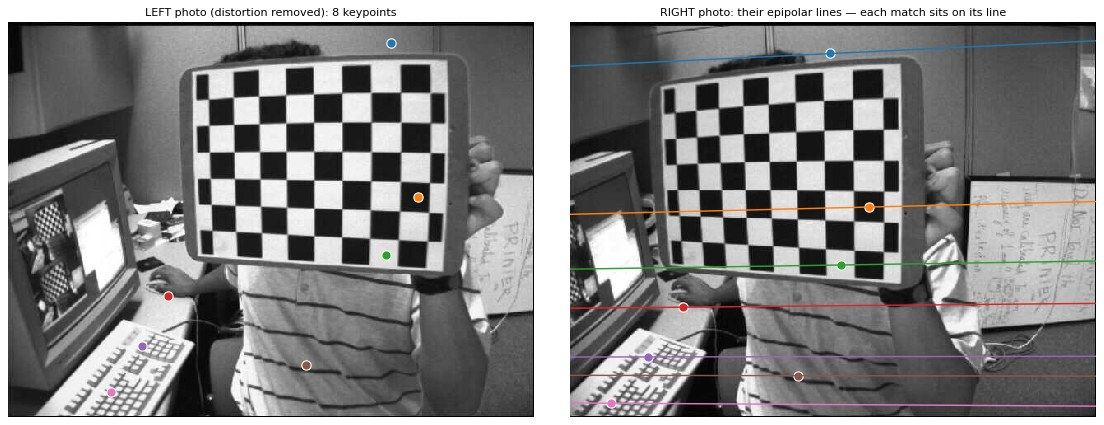

In [15]:
# --- 4.2 Step 2 — detect → match → RANSAC → fundamental matrix, and test it on points it never saw  [measured] ---
MATCHES = [match_sift(gl, gr) for gl, gr in zip(GRAY_L, GRAY_R)]  # SIFT matches of all 13 pairs (re-used in Part 5)
p_l, p_r = MATCHES[FOCUS]
F, inl, u_l, u_r = estimate_F(p_l, p_r, K1, d1, K2, d2)
print(
    f"pair {PAIR_IDS[FOCUS]}: {len(p_l)} matches after the ratio test → {inl.sum()} RANSAC inliers ({inl.mean():.0%})"
)


def epipolar_distance(F: np.ndarray, a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """Distance in pixels between each point and the epipolar line of its partner (average of both directions)."""
    a_h, b_h = np.c_[a, np.ones(len(a))], np.c_[b, np.ones(len(b))]
    line_in_b, line_in_a = a_h @ F.T, b_h @ F  # l' = F x   and   l = F^T x'
    d_b = np.abs(np.sum(line_in_b * b_h, axis=1)) / np.hypot(line_in_b[:, 0], line_in_b[:, 1])
    d_a = np.abs(np.sum(line_in_a * a_h, axis=1)) / np.hypot(line_in_a[:, 0], line_in_a[:, 1])
    return 0.5 * (d_a + d_b)


# Held-out test: the 54 board corners of this pair were NOT used to estimate F (and are accurate to ~0.1 px).
F_raw, mask_raw = cv2.findFundamentalMat(p_l, p_r, cv2.FM_RANSAC, 1.0, 0.999)  # without undistortion, for comparison
corners_l, corners_r = CORN_L[FOCUS].reshape(-1, 2), CORN_R[FOCUS].reshape(-1, 2)
e_raw = np.median(epipolar_distance(F_raw, corners_l, corners_r))
e_und = np.median(epipolar_distance(F, undistort_px(corners_l, K1, d1), undistort_px(corners_r, K2, d2)))
table(
    [
        ("raw pixels (distortion still in)", int(mask_raw.sum()), float(e_raw)),
        ("after undistortion (step 1)", int(inl.sum()), float(e_und)),
    ],
    ["F estimated from", "RANSAC inliers", "median epipolar error on the 54 held-out corners (px)"],
)

order = np.argsort(u_l[inl][:, 1])
pick = order[np.linspace(0, len(order) - 1, 8).astype(int)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
axes[0].imshow(GRAY_L[FOCUS], cmap="gray")
axes[1].imshow(GRAY_R[FOCUS], cmap="gray")
for (xa, ya), (xb, yb), c in zip(u_l[inl][pick], u_r[inl][pick], plt.cm.tab10(np.arange(8))):
    a_, b_, c_ = F @ np.array([xa, ya, 1.0])  # epipolar line a·x + b·y + c = 0 in the (undistorted) right image
    xs = np.array([0.0, IMG_SIZE[0] - 1])
    axes[0].scatter(xa, ya, s=70, color=c, edgecolor="white")
    axes[1].plot(xs, -(a_ * xs + c_) / b_, color=c, lw=1.3)
    axes[1].scatter(xb, yb, s=70, color=c, edgecolor="white")
axes[0].set_title("LEFT photo (distortion removed): 8 keypoints")
axes[1].set_title("RIGHT photo: their epipolar lines — each match sits on its line")
for ax in axes:
    ax.set_xlim(0, IMG_SIZE[0])
    ax.set_ylim(IMG_SIZE[1], 0)
    ax.axis("off")
plt.show()

In [16]:
# --- 4.3 Step 3a — from F to camera motion, and why a refinement step is needed  [measured] ----------
def rotation_error_deg(R: np.ndarray, R_ref: np.ndarray) -> float:
    """Angle (deg) of the rotation that takes R_ref to R."""
    return float(np.degrees(np.arccos(np.clip((np.trace(R @ R_ref.T) - 1) / 2, -1, 1))))


def direction_error_deg(t: np.ndarray, T_ref: np.ndarray) -> float:
    """Angle (deg) between two translation directions."""
    return float(np.degrees(np.arccos(np.clip(float(t @ T_ref) / np.linalg.norm(T_ref) / np.linalg.norm(t), -1, 1))))


R_plain, t_plain, n_front = pose_from_F(F, u_l, u_r, inl, K1, K2)  # F → E → (R, t_unit)
R_ref, t_ref = refine_pose(R_plain, t_plain, u_l[inl], u_r[inl], K1, K2)  # + Sampson refinement with K
rot_A_deg = np.degrees(np.linalg.norm(cv2.Rodrigues(CAL["R"])[0]))
print(f"Path A's calibrated pose, for comparison: rotation {rot_A_deg:.2f} deg, baseline {CAL['baseline'] * 100:.2f} cm\n")
table(
    [
        ("F → E → recoverPose", rotation_error_deg(R_plain, CAL["R"]), direction_error_deg(t_plain, CAL["T"])),
        (
            "   + refinement with K (5-parameter Sampson fit)",
            rotation_error_deg(R_ref, CAL["R"]),
            direction_error_deg(t_ref, CAL["T"]),
        ),
    ],
    [
        "Path B pose from the matches of this pair",
        "rotation error vs Path A (deg)",
        "translation direction error (deg)",
    ],
)
sv = np.linalg.svd(K2.T @ F @ K1, compute_uv=False)
print(f"\nsingular values of K2ᵀ F K1, normalised: {sv / sv[0]} — an exact essential matrix would be (1, 1, 0).")
print(
    "F was estimated WITHOUT using K (7 free parameters); the refinement adds that knowledge (a real camera motion has 5)."
)
print(
    f"|t| is {np.linalg.norm(t_ref):.2f} by construction: two photos alone cannot tell an 8 cm baseline from an 8 m one."
)
BASELINE_RULER_M = CAL["baseline"]  # an OUTSIDE measurement; here taken from the calibration session
print(f"We therefore supply the baseline LENGTH from outside: {BASELINE_RULER_M * 100:.2f} cm (in practice: a ruler).")

Path A's calibrated pose, for comparison: rotation 0.30 deg, baseline 8.37 cm

Path B pose from the matches of this pair         rotation error vs Path A (deg)  translation direction error (deg)
------------------------------------------------  ------------------------------  ---------------------------------
F → E → recoverPose                               0.2878                          3.066                            
   + refinement with K (5-parameter Sampson fit)  0.04896                         0.779                            

singular values of K2ᵀ F K1, normalised: [1.     0.9941 0.    ] — an exact essential matrix would be (1, 1, 0).
F was estimated WITHOUT using K (7 free parameters); the refinement adds that knowledge (a real camera motion has 5).
|t| is 1.00 by construction: two photos alone cannot tell an 8 cm baseline from an 8 m one.
We therefore supply the baseline LENGTH from outside: 8.37 cm (in practice: a ruler).


rectification of pair 01                    mean row error (px)  95th percentile (px)
------------------------------------------  -------------------  --------------------
no rectification (raw photos)               12.3                 15.32               
Path A   calibrated pose (12 pairs)         0.1716               0.4238              
Path B   F → E → recoverPose                0.6119               1.277               
Path B   + refinement with K                0.1611               0.3589              
Path B'  F only, stereoRectifyUncalibrated  0.5594               0.9758              
Row error = how far a corner's row in the right image is from its row in the left. A stereo matcher searches ONE row.


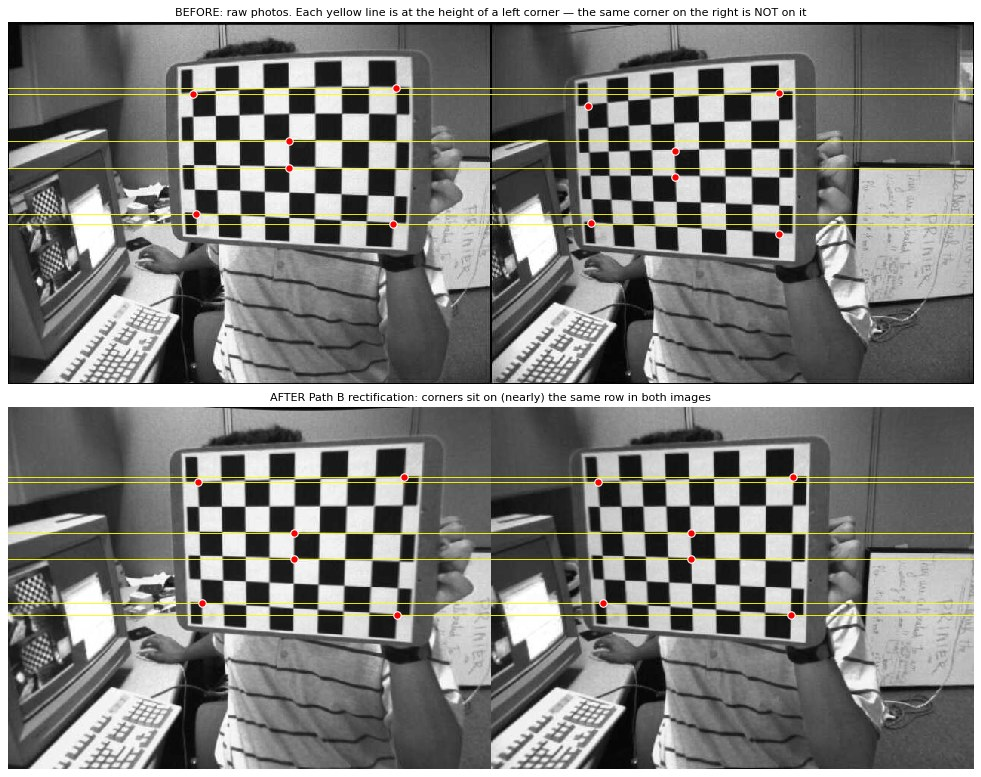

In [17]:
# --- 4.4 Step 3b — rectify, then CHECK the rectification before trusting any disparity  [measured] -----
RECT_B_PLAIN = build_rectification(K1, d1, K2, d2, R_plain, t_plain * BASELINE_RULER_M)
RECT_B = build_rectification(K1, d1, K2, d2, R_ref, t_ref * BASELINE_RULER_M)
_, H1, H2 = cv2.stereoRectifyUncalibrated(u_l[inl], u_r[inl], F, IMG_SIZE)  # Path B': F only, no K, no pose at all


def row_error_homography(k: int) -> np.ndarray:
    c_l = cv2.perspectiveTransform(undistort_px(CORN_L[k], K1, d1).reshape(-1, 1, 2).astype(np.float64), H1).reshape(
        -1, 2
    )
    c_r = cv2.perspectiveTransform(undistort_px(CORN_R[k], K2, d2).reshape(-1, 1, 2).astype(np.float64), H2).reshape(
        -1, 2
    )
    return np.abs(c_l[:, 1] - c_r[:, 1])


def row_error(rect: Optional[dict], k: int) -> np.ndarray:
    """|y_left − y_right| of the 54 board corners of pair k after rectification (0 = perfectly rectified)."""
    if rect is None:
        return np.abs(CORN_L[k].reshape(-1, 2)[:, 1] - CORN_R[k].reshape(-1, 2)[:, 1])
    c_l, c_r = rectified_points(rect, CORN_L[k], CORN_R[k])
    return np.abs(c_l[:, 1] - c_r[:, 1])


rows = []
for name, err in (
    ("no rectification (raw photos)", row_error(None, FOCUS)),
    ("Path A   calibrated pose (12 pairs)", row_error(RECT_A, FOCUS)),
    ("Path B   F → E → recoverPose", row_error(RECT_B_PLAIN, FOCUS)),
    ("Path B   + refinement with K", row_error(RECT_B, FOCUS)),
    ("Path B'  F only, stereoRectifyUncalibrated", row_error_homography(FOCUS)),
):
    rows.append((name, float(err.mean()), float(np.percentile(err, 95))))
table(rows, ["rectification of pair 01", "mean row error (px)", "95th percentile (px)"])
print(
    "Row error = how far a corner's row in the right image is from its row in the left. A stereo matcher searches ONE row."
)

RECT_L, RECT_R = rectify_images(RECT_B, GRAY_L[FOCUS], GRAY_R[FOCUS])
c_l_b, c_r_b = rectified_points(RECT_B, CORN_L[FOCUS], CORN_R[FOCUS])
fig, axes = plt.subplots(2, 1, figsize=(13, 9.6), constrained_layout=True)
for ax, pair, (cl, cr), title in (
    (axes[0], np.hstack([GRAY_L[FOCUS], GRAY_R[FOCUS]]), (corners_l, corners_r),
     "BEFORE: raw photos. Each yellow line is at the height of a left corner — the same corner on the right is NOT on it"),
    (axes[1], np.hstack([RECT_L, RECT_R]), (c_l_b, c_r_b),
     "AFTER Path B rectification: corners sit on (nearly) the same row in both images"),
):
    ax.imshow(pair, cmap="gray")
    for i in (0, 8, 22, 31, 45, 53):
        ax.axhline(cl[i, 1], color="yellow", lw=0.8)
        ax.scatter(
            [cl[i, 0], cr[i, 0] + IMG_SIZE[0]], [cl[i, 1], cr[i, 1]], s=45, color="red", edgecolor="white", zorder=3
        )
    ax.set_title(title)
    ax.axis("off")
plt.show()

Pair 01, board at 0.383 m, identical SGBM settings in every row:
rectification used           corners matched  median depth error  relative  row error
---------------------------  ---------------  ------------------  --------  ---------
Path A  calibrated pose      52/54            0.5 mm              0.15 %    0.17 px  
Path B  F → E → recoverPose  48/54            14.0 mm             3.53 %    0.61 px  
Path B  + refinement with K  50/54            1.7 mm              0.44 %    0.16 px  


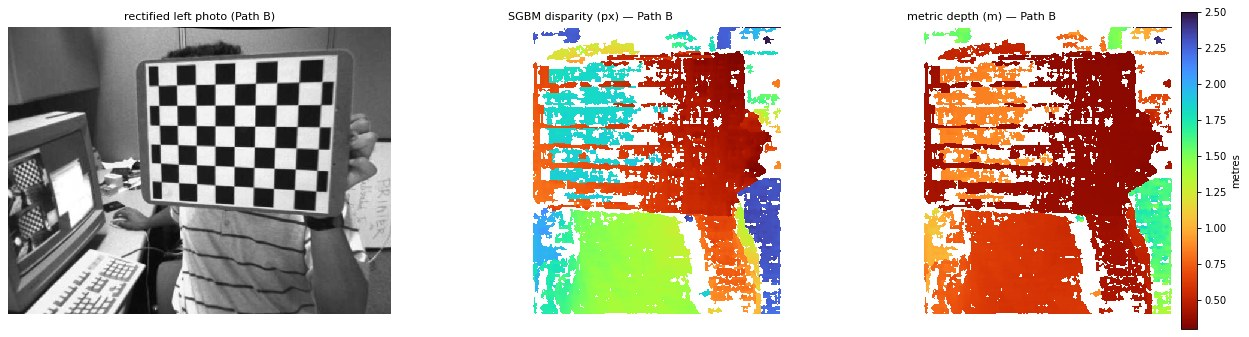

In [18]:
# --- 4.5 Step 4 — the SAME matcher as Path A: disparity and depth  [measured] -------------------------
M_B = measure_pair(RECT_B, FOCUS, K1, d1, NUM_DISP_RIG, keep_maps=True)
M_B_PLAIN = measure_pair(RECT_B_PLAIN, FOCUS, K1, d1, NUM_DISP_RIG)
rows = []
for name, m in (
    ("Path A  calibrated pose", M_A),
    ("Path B  F → E → recoverPose", M_B_PLAIN),
    ("Path B  + refinement with K", M_B),
):
    s = summarise(m)
    rows.append(
        (
            name,
            f"{s['matched']}/54",
            f"{s['median_mm']:.1f} mm" if s["matched"] >= MIN_MATCHED else "failed",
            f"{s['median_pct']:.2f} %" if s["matched"] >= MIN_MATCHED else "failed",
            f"{s['row_px']:.2f} px",
        )
    )
print(f"Pair {PAIR_IDS[FOCUS]}, board at {S_A['z_mean']:.3f} m, identical SGBM settings in every row:")
table(rows, ["rectification used", "corners matched", "median depth error", "relative", "row error"])

depth_map_B = np.where(
    M_B["disp"] > 0, depth_from_disparity(np.maximum(M_B["disp"], 1e-6), RECT_B["f"], RECT_B["baseline"]), np.nan
)
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.1), constrained_layout=True)
axes[0].imshow(M_B["left"], cmap="gray")
axes[0].set_title("rectified left photo (Path B)")
axes[1].imshow(np.where(M_B["disp"] > 0, M_B["disp"], np.nan), cmap="turbo")
axes[1].set_title("SGBM disparity (px) — Path B")
handle = axes[2].imshow(depth_map_B, cmap="turbo_r", vmin=0.3, vmax=2.5)
axes[2].set_title("metric depth (m) — Path B")
fig.colorbar(handle, ax=axes[2], fraction=0.046, pad=0.02, label="metres")
for ax in axes:
    ax.axis("off")
plt.show()

**Read the result (Path B, one pair).**
- Our calibration matches OpenCV's reference file to a few hundredths of a percent — checked *before* anything downstream.
- The epipolar constraint holds on points $F$ never saw (about half a pixel). Removing lens distortion first helps only slightly on this pair — the distortion
  of this lens is moderate near the image centre where most matches lie — but it is the correct order, because the constraint describes straight light rays.
- $F \to E \to (R,t)$ gives a usable first pose, but a clearly worse rectification than Path A. **Refining the pose with the known $K$** removes most of the remaining error: $F$ is a 7-parameter object estimated without
  $K$, while a real camera motion has only 5 parameters — using that knowledge averages the noise down.
- Path B's depth error on this pair is larger than Path A's, from a rectification that is a little off, with the *same* matcher. Part 5 shows how typical this pair is — **it is a good one**.

---
# Part 5 — Path A vs. Path B: a quantitative comparison and an error attribution  *(§11 · rubric 25 %)*

The brief asks for two things: a **number-based comparison** of the two paths, and an **attribution** — *where does each error come from?*
It separates two families of error sources:

| Family | Examples | Present in |
|---|---|---|
| **Calibration / rectification** (pipeline set-up) | wrong $K$, wrong relative pose $R, t$, imperfect rectification | mainly **Path B** (Path A is given them) |
| **Disparity estimation** (the matcher itself) | noise, textureless regions, repeated patterns, occlusions | **both** paths |

A comparison that only *reports* two error numbers cannot tell them apart. We attribute the error with **controlled experiments**:
1. **5.1** — repeat the comparison on all **13 independent test pairs** (leave-one-pair-out), not on one lucky pair, and ablate Path B stage by stage.
2. **5.2** — find *why* Path B fails when it fails, using diagnostics that do not look at the depth result.
3. **5.3** — **inject** known pose errors into the *correct* calibration and watch the depth error appear: how accurate must the pose be?
4. **5.4** — measure how errors of the intrinsics $K$ propagate (the §11 / PP17 tip about varied checkerboard poses).
5. **5.5** — measure the matcher's own error (benchmark, and a *different* matcher) to separate it from everything above.

*Needs:* Parts 0–4.

13 folds × 4 methods in 13 s
Median depth error at the 54 board corners, as % of the true distance.
'failed' = fewer than 10 corners matched, or a median error above 20 %
pair  board at  Path A %  Path B, F→E only %  Path B (refined) %  Path B, pooled (ext.) %  A matched  B matched  pool matched
----  --------  --------  ------------------  ------------------  -----------------------  ---------  ---------  ------------
01    0.38 m    0.15      3.53                0.44                0.29                     52         50         44          
02    0.28 m    0.18      failed              failed              0.37                     49         0          47          
03    0.28 m    0.17      failed              failed              0.22                     48         0          46          
04    0.30 m    0.17      failed              failed              3.26                     41         0          39          
05    0.27 m    0.13      failed              failed              0.81   

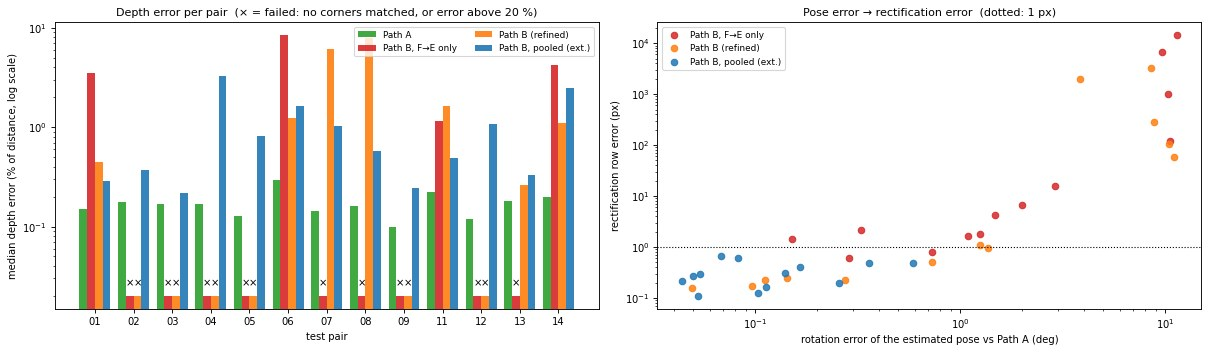

In [19]:
# --- 5.1 All 13 pairs, leave-one-pair-out: Path A, Path B (stage by stage) and Path B with pooled matches  [measured] ---
def pose_errors(R: np.ndarray, t: np.ndarray, cal: dict) -> tuple:
    """(rotation error in deg, translation-direction error in deg) of an estimated pose relative to the calibrated one."""
    return rotation_error_deg(R, cal["R"]), direction_error_deg(t, cal["T"])


def evaluate_fold(k: int) -> dict:
    """Test pair k. Everything calibrated from photos is re-estimated without pair k (Part 1.4)."""
    cal = leave_one_out(k)
    K1, d1, K2, d2 = cal["K1"], cal["d1"], cal["K2"], cal["d2"]
    out = {"cal": cal}
    out["A"] = {"m": measure_pair(build_rectification(K1, d1, K2, d2, cal["R"], cal["T"]), k, K1, d1, NUM_DISP_RIG)}
    others = [j for j in range(N_PAIRS) if j != k]
    sources = {  # which matches estimate the pose?
        "B": MATCHES[k],  # PP17's Path B: the test pair alone
        "B_pool": (
            np.vstack([MATCHES[j][0] for j in others]),
            np.vstack([MATCHES[j][1] for j in others]),
        ),  # all 12 other pairs
    }
    for name, (pl, pr) in sources.items():
        est = estimate_pose_B(pl, pr, K1, d1, K2, d2, refine=False)
        if not est["ok"]:
            out[name] = out[name + "_plain"] = {"ok": False}
            continue
        R0, t0 = est["R"], est["t"]
        R1, t1 = refine_pose(R0, t0, est["u_l"][est["inliers"]], est["u_r"][est["inliers"]], K1, K2)
        for label, (R, t) in ((name + "_plain", (R0, t0)), (name, (R1, t1))):
            rect = build_rectification(
                K1, d1, K2, d2, R, t * cal["baseline"]
            )  # baseline LENGTH from outside (Part 4.3)
            rot, dirn = pose_errors(R, t, cal)
            out[label] = {"ok": True, "m": measure_pair(rect, k, K1, d1, NUM_DISP_RIG), "rot": rot, "dir": dirn,
                          "n_inl": est["n_inliers"], "est": est, "R": R, "t": t}
    return out


t0 = time.time()
FOLDS = [evaluate_fold(k) for k in range(N_PAIRS)]
print(f"{N_PAIRS} folds × 4 methods in {time.time() - t0:.0f} s")
LABELS = {"A": "Path A", "B_plain": "Path B, F→E only", "B": "Path B (refined)", "B_pool": "Path B, pooled (ext.)"}


def summary_of(fold: dict, name: str) -> Optional[dict]:
    if not fold[name].get("ok", True):
        return None
    s = summarise(fold[name]["m"])
    worked = s["matched"] >= MIN_MATCHED and s["median_pct"] <= GROSS_ERR_PCT
    return s if worked else None  # None = failed: (almost) no corners matched, or the depth is grossly wrong


def cell(fold: dict, name: str, key: str = "median_pct", fmt: str = "{:.2f}") -> str:
    s = summary_of(fold, name)
    return "failed" if s is None else fmt.format(s[key])


rows = []
for k, fold in enumerate(FOLDS):
    rows.append(
        (
            PAIR_IDS[k],
            f"{summarise(fold['A']['m'])['z_mean']:.2f} m",
            *[cell(fold, n) for n in LABELS],
            *[f"{fold[n]['m']['matched']}" if fold[n].get("ok", True) else "-" for n in ("A", "B", "B_pool")],
        )
    )
print("Median depth error at the 54 board corners, as % of the true distance.")
print(f"'failed' = fewer than {MIN_MATCHED} corners matched, or a median error above {GROSS_ERR_PCT:.0f} %")
table(rows, ["pair", "board at", *[f"{v} %" for v in LABELS.values()], "A matched", "B matched", "pool matched"])

print("\nSummary over the 13 pairs")
rows = []
for name, label in LABELS.items():
    ss = [summary_of(f, name) for f in FOLDS]
    ok_ = [s for s in ss if s is not None]
    row_px = [summarise(f[name]["m"])["row_px"] for f in FOLDS if f[name].get("ok", True)]
    rows.append((label, f"{len(ok_)}/{N_PAIRS}", f"{np.median([s['median_pct'] for s in ok_]):.2f} %" if ok_ else "-",
                 f"{np.median([s['median_mm'] for s in ok_]):.1f} mm" if ok_ else "-", f"{np.median(row_px):.2f} px"))
table(
    rows,
    ["method", "pairs that worked", "median depth error (working pairs)", "= in mm", "median row error (all pairs)"],
)
print("\nPose of Path B relative to Path A's calibrated pose (degrees)")
rows = []
for name in ("B_plain", "B", "B_pool"):
    rots = [f[name]["rot"] for f in FOLDS if f[name]["ok"]]
    dirs = [f[name]["dir"] for f in FOLDS if f[name]["ok"]]
    rows.append(
        (LABELS[name], f"{np.median(rots):.2f}", f"{np.max(rots):.2f}", f"{np.median(dirs):.2f}", f"{np.max(dirs):.2f}")
    )
table(rows, ["method", "rotation error: median", "worst pair", "direction error: median", "worst pair"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), constrained_layout=True)
width = 0.2
for j, (name, colour) in enumerate(
    (("A", "tab:green"), ("B_plain", "tab:red"), ("B", "tab:orange"), ("B_pool", "tab:blue"))
):
    vals = np.array([summary_of(f, name)["median_pct"] if summary_of(f, name) else np.nan for f in FOLDS])
    axes[0].bar(
        np.arange(N_PAIRS) + (j - 1.5) * width,
        np.where(np.isnan(vals), 0.02, vals),
        width,
        color=colour,
        label=LABELS[name],
        alpha=0.9,
    )
    for i in np.nonzero(np.isnan(vals))[0]:
        axes[0].text(i + (j - 1.5) * width, 0.025, "×", ha="center", color="k", fontsize=9)
axes[0].set_yscale("log")
axes[0].set_xticks(range(N_PAIRS), PAIR_IDS)
axes[0].set_xlabel("test pair")
axes[0].set_ylabel("median depth error (% of distance, log scale)")
axes[0].set_title("Depth error per pair  (× = failed: no corners matched, or error above 20 %)")
axes[0].legend(fontsize=8, ncol=2)
for name, colour in (("B_plain", "tab:red"), ("B", "tab:orange"), ("B_pool", "tab:blue")):
    axes[1].scatter(
        [f[name]["rot"] for f in FOLDS if f[name]["ok"]],
        [summarise(f[name]["m"])["row_px"] for f in FOLDS if f[name]["ok"]],
        color=colour,
        s=34,
        label=LABELS[name],
        alpha=0.85,
    )
axes[1].axhline(1.0, color="k", ls=":", lw=1)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("rotation error of the estimated pose vs Path A (deg)")
axes[1].set_ylabel("rectification row error (px)")
axes[1].set_title("Pose error → rectification error  (dotted: 1 px)")
axes[1].legend(fontsize=8)
plt.show()

In [20]:
# --- 5.2 Why does Path B fail on some pairs?  Diagnostics that never look at the depth result  [measured] ---
def coverage(points: np.ndarray) -> float:
    """Share of the image area inside the convex hull of the points — are the matches spread over the image?"""
    return float(cv2.contourArea(cv2.convexHull(points.astype(np.float32))) / (IMG_SIZE[0] * IMG_SIZE[1]))


def disparity_spread(u_l: np.ndarray, u_r: np.ndarray) -> float:
    """p90 − p10 of the matches' horizontal shifts (px): wide = scene has depth, ~0 = all points in one plane."""
    d = u_l[:, 0] - u_r[:, 0]
    return float(np.percentile(d, 90) - np.percentile(d, 10))


diag = []
for k, fold in enumerate(FOLDS):
    if not fold["B"]["ok"]:
        continue
    est = fold["B"]["est"]
    keep = est["inliers"]
    cov = coverage(est["u_l"][keep])
    spread = disparity_spread(est["u_l"][keep], est["u_r"][keep])
    status = "worked" if summary_of(fold, "B") else "failed"
    diag.append((k, est["n_inliers"], cov, spread, fold["B"]["rot"], fold["B"]["dir"], status))
table(
    [(PAIR_IDS[k], n, f"{c:.2f}", f"{s:.0f} px", f"{r:.2f}", f"{d:.2f}", status) for k, n, c, s, r, d, status in diag],
    [
        "pair",
        "RANSAC inliers",
        "image coverage",
        "disparity spread",
        "rotation error (deg)",
        "direction error (deg)",
        "Path B",
    ],
)
from scipy import stats

arr = np.array([(n, c, s, r) for _, n, c, s, r, _, _ in diag])
for j, name in ((0, "number of inliers"), (1, "image coverage"), (2, "disparity spread")):
    rho, p = stats.spearmanr(arr[:, j], arr[:, 3])
    print(f"Spearman correlation of rotation error with {name:>17}: rho = {rho:+.2f} (p = {p:.3f}, n = {len(arr)})")

pair  RANSAC inliers  image coverage  disparity spread  rotation error (deg)  direction error (deg)  Path B
----  --------------  --------------  ----------------  --------------------  ---------------------  ------
01    289             0.67            74 px             0.05                  0.78                   worked
02    155             0.41            16 px             8.82                  85.55                  failed
03    155             0.29            19 px             8.50                  92.81                  failed
04    149             0.20            36 px             10.49                 99.61                  failed
05    42              0.44            71 px             3.84                  66.51                  failed
06    310             0.73            85 px             0.11                  0.80                   worked
07    300             0.53            90 px             0.73                  0.35                   worked
08    131             0.60  

Pair 01: error injected into Path A's calibration. Each cell: corners matched / median depth error
error injected             0.05 deg      0.1 deg       0.25 deg       0.5 deg        1 deg         
-------------------------  ------------  ------------  -------------  -------------  --------------
rotation about x (pitch)   49/54  0.3 %  43/54  0.6 %  29/54  36.3 %  10/54  36.3 %  3/54  failed  
rotation about y (yaw)     51/54  0.4 %  53/54  0.8 %  52/54  1.9 %   52/54  3.8 %   50/54  7.3 %  
rotation about z (roll)    51/54  0.1 %  51/54  0.1 %  48/54  0.3 %   44/54  0.6 %   28/54  1.1 %  
direction about x (pitch)  51/54  0.1 %  51/54  0.1 %  52/54  0.1 %   52/54  0.1 %   53/54  0.2 %  
direction about y (yaw)    52/54  0.1 %  52/54  0.1 %  52/54  0.1 %   54/54  0.2 %   47/54  0.3 %  
direction about z (roll)   52/54  0.2 %  51/54  0.2 %  53/54  0.3 %   40/54  0.8 %   38/54  114.6 %
(no injected error: 52/54, 0.15 %)

Rule of thumb for a yaw error δ: every disparity shifts by ≈ f·δ 

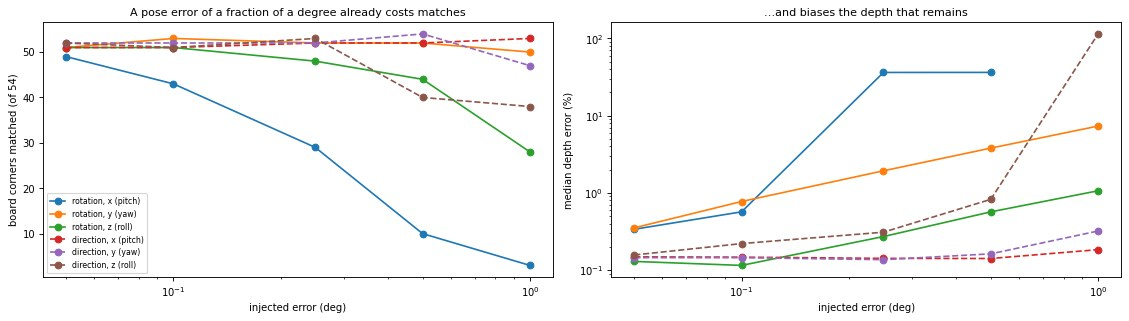

In [21]:
# --- 5.3 Inject KNOWN pose errors into the correct calibration: how accurate must the pose be?  [measured] ---
def perturbed_rect(cal: dict, kind: str, axis: int, deg: float) -> dict:
    """Path A's calibration with one deliberate error: the right camera's rotation (kind='rotation') or the direction
    of the baseline (kind='direction') is turned by `deg` degrees about image axis x (pitch), y (yaw) or z (roll)."""
    rot = cv2.Rodrigues(np.eye(3)[axis] * np.radians(deg))[0]
    R, T = (rot @ cal["R"], cal["T"]) if kind == "rotation" else (cal["R"], rot @ cal["T"])
    return build_rectification(cal["K1"], cal["d1"], cal["K2"], cal["d2"], R, T)


ANGLES = (0.05, 0.1, 0.25, 0.5, 1.0)
AXES = {"x (pitch)": 0, "y (yaw)": 1, "z (roll)": 2}
cal_f = CAL
base_mm = summarise(M_A)
sens = {}
for kind in ("rotation", "direction"):
    for axis_name, axis in AXES.items():
        sens[(kind, axis_name)] = [
            summarise(measure_pair(perturbed_rect(cal_f, kind, axis, a), FOCUS, K1, d1, NUM_DISP_RIG)) for a in ANGLES
        ]

print(
    f"Pair {PAIR_IDS[FOCUS]}: error injected into Path A's calibration. Each cell: corners matched / median depth error"
)
rows = []
for (kind, axis_name), res in sens.items():
    rows.append(
        (
            f"{kind} about {axis_name}",
            *[
                f"{s['matched']}/54  " + (f"{s['median_pct']:.1f} %" if s["matched"] >= MIN_MATCHED else "failed")
                for s in res
            ],
        )
    )
table(rows, ["error injected", *[f"{a:g} deg" for a in ANGLES]])
print(f"(no injected error: {base_mm['matched']}/54, {base_mm['median_pct']:.2f} %)")
d_typ = RECT_A["f"] * RECT_A["baseline"] / base_mm["z_mean"]  # typical disparity of the board corners
shift_px_per_deg = RECT_A["f"] * np.radians(1)  # a yaw error of δ shifts every disparity by about f·δ
yaw_pred = 100 * shift_px_per_deg / d_typ
yaw_1deg = sens[("rotation", "y (yaw)")][-1]
print(f"\nRule of thumb for a yaw error δ: every disparity shifts by ≈ f·δ = {shift_px_per_deg:.1f} px per degree,")
print(f"so at the board's typical disparity of {d_typ:.0f} px the depth error is ≈ {yaw_pred:.1f} % per degree.")
print(f"Check: predicted ≈ {yaw_pred:.1f} % per degree, measured {yaw_1deg['median_pct']:.1f} % at 1 deg.")
print("Pitch and roll errors do not shift disparities; they move corners to other ROWS,")
print("and a matcher that searches one row loses them.")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.9), constrained_layout=True)
for (kind, axis_name), res in sens.items():
    ls = "-" if kind == "rotation" else "--"
    axes[0].plot(ANGLES, [s["matched"] for s in res], ls, marker="o", label=f"{kind}, {axis_name}")
    axes[1].plot(
        ANGLES,
        [s["median_pct"] if s["matched"] >= MIN_MATCHED else np.nan for s in res],
        ls,
        marker="o",
        label=f"{kind}, {axis_name}",
    )
axes[0].set_xscale("log")
axes[0].set_xlabel("injected error (deg)")
axes[0].set_ylabel("board corners matched (of 54)")
axes[0].set_title("A pose error of a fraction of a degree already costs matches")
axes[0].legend(fontsize=7)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("injected error (deg)")
axes[1].set_ylabel("median depth error (%)")
axes[1].set_title("…and biases the depth that remains")
plt.show()

In [22]:
# --- 5.4 How do errors of the intrinsics K propagate?  Few vs. many checkerboard photos  [measured] -----
rng_cal = np.random.default_rng(SEED)
pool = [j for j in range(N_PAIRS) if j != FOCUS]
rows, K_SUBSET = [], {}
for n_photos in (3, 5, 8, 12):
    f_vals, errs, failed = [], [], 0
    for _ in range(1 if n_photos == 12 else 8):  # 8 random choices of n photo pairs (12 → only one choice exists)
        chosen = sorted(rng_cal.choice(pool, size=n_photos, replace=False).tolist())
        try:
            sub = leave_one_out(FOCUS, subset=chosen)
            rect = build_rectification(sub["K1"], sub["d1"], sub["K2"], sub["d2"], sub["R"], sub["T"])
            s = summarise(measure_pair(rect, FOCUS, K1, d1, NUM_DISP_RIG))  # truth always from the 12-photo calibration
        except cv2.error:
            failed += 1
            continue
        f_vals.append(sub["K1"][0, 0])
        if s["matched"] >= MIN_MATCHED:
            errs.append(s["median_pct"])
    worst_fx = 100 * float(np.max(np.abs(np.array(f_vals) - K1[0, 0])) / K1[0, 0])
    K_SUBSET[n_photos] = {"worst_fx": worst_fx, "median": float(np.median(errs)), "worst": float(np.max(errs))}
    rows.append((n_photos, f"{np.std(f_vals):.1f} px" if len(f_vals) > 1 else "-", f"{worst_fx:.1f} %",
                 f"{np.median(errs):.2f} %" if errs else "-", f"{np.max(errs):.2f} %" if errs else "-", failed))
print("Path A with a calibration built from only n photo pairs (random subsets), tested on pair 01:")
table(
    rows,
    [
        "photo pairs used",
        "std of fx",
        "worst fx error",
        "median depth error",
        "worst depth error",
        "calibrations that crashed",
    ],
)
print(
    "A focal-length error of ε scales every depth by ε, so the 'worst fx error' column is the depth bias it can cause on its own."
)

Path A with a calibration built from only n photo pairs (random subsets), tested on pair 01:
photo pairs used  std of fx  worst fx error  median depth error  worst depth error  calibrations that crashed
----------------  ---------  --------------  ------------------  -----------------  -------------------------
3                 6.8 px     2.5 %           1.01 %              2.01 %             0                        
5                 2.1 px     0.6 %           0.25 %              0.50 %             0                        
8                 1.5 px     0.5 %           0.31 %              0.39 %             0                        
12                -          0.0 %           0.15 %              0.15 %             0                        
A focal-length error of ε scales every depth by ε, so the 'worst fx error' column is the depth bias it can cause on its own.


In [23]:
# --- 5.5 The matcher's own error — measured on a benchmark and with a DIFFERENT matcher  [measured] ----
# (a) The matcher floor in pixels, from Part 2 (ground truth, no calibration involved), converted to the rig's board distance.
floor_px = SCORES_A[("cones", "OpenCV StereoSGBM 5x5")]["median_vis"]
floor_px_t = SCORES_A[("teddy", "OpenCV StereoSGBM 5x5")]["median_vis"]
fB = RECT_A["f"] * RECT_A["baseline"]
z_b = S_A["z_mean"]
print(
    f"(a) SGBM median disparity error on benchmark pixels both cameras see: Cones {floor_px:.2f} px, Teddy {floor_px_t:.2f} px."
)
print(
    f"    At the rig's board distance ({z_b:.2f} m, f·B = {fB:.1f} px·m) a disparity error δd gives a depth error of Z²/(f·B)·δd:"
)
print(
    f"    → {fmt_len(z_b**2 / fB * floor_px)} (Cones) / {fmt_len(z_b**2 / fB * floor_px_t)} (Teddy). Path A measured {S_A['median_mm']:.2f} mm on this pair."
)


# (b) A different matcher on the same rectified pair: our from-scratch block matcher (9x9 SAD), for both paths.
def scratch_on_rig(gray_l: np.ndarray, gray_r: np.ndarray, num_disp: int) -> np.ndarray:
    return scratch_matcher(gray_l, gray_r, num_disp, 9)


rows = []
for name, rect in (("Path A  calibrated pose", RECT_A), ("Path B  refined", RECT_B)):
    s_sgbm = summarise(measure_pair(rect, FOCUS, K1, d1, NUM_DISP_RIG))
    s_ours = summarise(measure_pair(rect, FOCUS, K1, d1, NUM_DISP_RIG, matcher=scratch_on_rig))
    rows.append(
        (
            name,
            f"{s_sgbm['matched']}/54",
            f"{s_sgbm['median_mm']:.1f} mm",
            f"{s_ours['matched']}/54",
            f"{s_ours['median_mm']:.1f} mm",
        )
    )
print("\n(b) Same rectified pairs, two different matchers (pair 01):")
table(
    rows,
    [
        "rectification",
        "SGBM: matched",
        "SGBM: median error",
        "our block matcher: matched",
        "our block matcher: median error",
    ],
)

(a) SGBM median disparity error on benchmark pixels both cameras see: Cones 0.19 px, Teddy 0.19 px.
    At the rig's board distance (0.38 m, f·B = 43.5 px·m) a disparity error δd gives a depth error of Z²/(f·B)·δd:
    → 0.6 mm (Cones) / 0.6 mm (Teddy). Path A measured 0.54 mm on this pair.

(b) Same rectified pairs, two different matchers (pair 01):
rectification            SGBM: matched  SGBM: median error  our block matcher: matched  our block matcher: median error
-----------------------  -------------  ------------------  --------------------------  -------------------------------
Path A  calibrated pose  52/54          0.5 mm              54/54                       1.0 mm                         
Path B  refined          50/54          1.7 mm              54/54                       1.8 mm                         


In [24]:
# --- 5.6 The error budget: every source, its measured size, and where it was measured  [measured] ------
def working(name: str) -> list:
    return [s for s in (summary_of(f, name) for f in FOLDS) if s is not None]


A_all, B_all, P_all = working("A"), working("B"), working("B_pool")
med_a = float(np.median([s["median_pct"] for s in A_all]))
med_b = float(np.median([s["median_pct"] for s in B_all]))
med_p = float(np.median([s["median_pct"] for s in P_all]))
budget = [
    ("disparity estimation (the matcher)", "both",
     f"Path A, 13 pairs: median {med_a:.2f} % ({np.median([s['median_mm'] for s in A_all]):.1f} mm)",
     f"benchmark floor {floor_px:.2f} px ≙ {fmt_len(z_b**2 / fB * floor_px)} on pair 01 (5.5a); another matcher: same order (5.5b)"),
    ("intrinsics K and distortion", "both",
     f"{f_dev:.2%} vs OpenCV's reference file (4.1)",
     "photos used → worst fx error / worst depth error: "
     + "; ".join(f"{n}: {v['worst_fx']:.1f} % / {v['worst']:.1f} %" for n, v in K_SUBSET.items() if n < 12) + " (5.4)"),
    ("length of the baseline", "both",
     "not measured: taken from the calibration",
     "depth ∝ B, so a relative error ε in B gives ε in depth (§4.1)"),
    ("relative pose → rectification, F from the pair alone", "Path B",
     f"{len(B_all)}/{N_PAIRS} pairs worked, median {med_b:.2f} % ({np.median([s['median_mm'] for s in B_all]):.1f} mm)",
     "pose error of a fraction of a degree = lost matches or a few % bias (5.3); bad when matches cover little of the image (5.2)"),
    ("same, F from pooled matches (extension)", "Path B",
     f"{len(P_all)}/{N_PAIRS} pairs worked, median {med_p:.2f} % ({np.median([s['median_mm'] for s in P_all]):.1f} mm)",
     "more and better spread matches remove every failure (5.1, 5.2)"),
]
table([(a, b, c, d) for a, b, c, d in budget], ["error source", "in", "measured size", "evidence"])

error source                                          in      measured size                               evidence                                                                                                                   
----------------------------------------------------  ------  ------------------------------------------  ---------------------------------------------------------------------------------------------------------------------------
disparity estimation (the matcher)                    both    Path A, 13 pairs: median 0.17 % (0.5 mm)    benchmark floor 0.19 px ≙ 0.6 mm on pair 01 (5.5a); another matcher: same order (5.5b)                                     
intrinsics K and distortion                           both    0.03% vs OpenCV's reference file (4.1)      photos used → worst fx error / worst depth error: 3: 2.5 % / 2.0 %; 5: 0.6 % / 0.5 %; 8: 0.5 % / 0.4 % (5.4)               
length of the baseline                                both    not measured: take

---
# Part 5.7 — Written discussion: where the error comes from

*All numbers below are printed by the cells above; `[measured]` unless marked otherwise.*

### What was compared
Path A and Path B were run on the **same 13 stereo photo pairs**, with the same matcher (SGBM) and the same settings. For each test pair, every
quantity estimated from checkerboard photos (intrinsics and, for Path A, the stereo pose) was re-estimated **without that pair**. Truth is the
board's own distance (`solvePnP`). Path B takes the *direction* of the baseline from the matches and the *length* of the baseline from outside
(two photos cannot know it).

### Findings
1. **Path A is accurate to the matcher's floor.** Median depth error 0.17 % (≈ 0.5 mm at 0.3–0.4 m), on all 13 pairs. The *independent* benchmark measurement
   of the matcher (0.19 px median disparity error on Middlebury) predicts 0.6 mm at this distance. The two agree, so **almost all of Path A's error is disparity-estimation error** and
   the calibration it is given contributes very little.
2. **Path B, as the brief defines it, is much less reliable.** With $F$ estimated from the test pair alone, only 4 of 13 pairs give a usable depth after `F → E → recoverPose`;
   adding one refinement step that uses the known $K$ gives 7 of 13, with a median error of 1.21 % (≈ 4–5 mm) — about 7× Path A. On five of the other six pairs the pose is wrong by 4–11° and the
   rectification is useless (the matcher finds no board corner at all). On the sixth (pair 12) the pose error is only 1.25°, yet the matcher puts the corners at grossly wrong disparities (median error 195 %).
3. **The matcher is not the cause.** It is identical in both paths. A different matcher (our block matcher) gives the same ordering: 1.0 mm (Path A) vs. 1.8 mm (Path B) on pair 01 (5.5b).
4. **The intrinsics are not the main cause either.** Our $K$ matches OpenCV's reference file to 0.03 %. Intrinsics *can* matter when the calibration is poor: with 3 checkerboard photos the focal length scatters by up to 2.5 %
   and the depth is off by 1–2 %; with 5 or more photos the focal length stays within 0.6 % and the depth within about 0.5 % (5.4). That is the PP17 tip about varied checkerboard poses, quantified. Because $Z \propto f$, a focal-length error shows up one-to-one as a depth error.
5. **The dominant Path B-specific error is the relative pose, i.e. rectification quality.** The injection experiments (5.3) show how little pose error the matcher tolerates:
   a **yaw** error shifts every disparity by ≈ $f\cdot\delta$ (9.1 px per degree) and biases depth by ≈ 8 % per degree (predicted) — 7.4 % measured at 1°; a **pitch** error moves corners to other image rows, and a matcher that searches one row loses them:
   at 0.1° only 42 of 54 corners are still matched, at 0.25° only 31 and their depth is wrong (median error 111 %). To stay under about 1 % depth error the rotation must be right to roughly 0.1°.
   Path B's pose errors from a single pair (median 1.25°, worst 11°) are one to two orders of magnitude above that.
6. **Why the pose is wrong on some pairs.** Five of the six failing pairs fit a simple picture — their matches cover little of the image, are few, or lie at one depth. (Pair 12 does not: 152 inliers, coverage 0.56, wide
   disparity spread; its 1.25° pose error is moderate and the matcher punishes it — the diagnostics are a warning sign, not a guarantee.) Image coverage of the RANSAC inliers is strongly (rank) correlated with
   pose error (Spearman ρ = −0.80, n = 13); the number of inliers and the disparity spread correlate more weakly (ρ = −0.58, −0.55). Correlation alone cannot prove the cause, but a controlled change does:
   **pooling the matches of the 12 other pairs** (the rig does not move between photos) removes all six failures, drops the pose error to a median of 0.10° (worst 0.59°) and the depth error to 0.57 %.
7. **Using $K$ inside the pose estimate pays off.** $F$ has 7 free parameters and is estimated without $K$; a camera motion has 5. The 5-parameter refinement cut the median row error from 4.3 px to 0.96 px.

### Error attribution — calibration and rectification vs. disparity estimation
| Source | Family | Size here |
|---|---|---|
| disparity estimation (matcher) | common to both paths | ≈ 0.2 % at 0.4 m; the whole of Path A's error |
| intrinsics $K$ | calibration | 0.03 % vs. the reference file; depth 1–2 % when only 3 photos are used, ≈ 0.5 % or less from 5 photos |
| baseline length | calibration | not measured (taken from outside) — scales depth 1:1 |
| relative pose → rectification | **Path B only** | median 1.2 % when it works, wrong on 6 of 13 pairs; 0.57 % with pooled matches |

The *excess* of Path B over Path A (≈ 1 percentage point, or total failure) is therefore **calibration/rectification error, not disparity-estimation error** — the matcher and the scene are the same in both.
The remaining gap of the pooled variant (0.57 % vs. 0.17 %) is consistent with its residual rotation error of ≈ 0.1°: the injected 0.1° yaw error gives ≈ 0.8 % (5.3).

### Limits of this study
- **One rig, 13 pairs.** Correlations (5.2) are rank correlations on 13 points; the pooling experiment is the stronger evidence.
- **Baseline length** in Path B comes from the calibration session. A real Path B needs a ruler; its error would add one-to-one to the depth error.
- **The reference** (solvePnP on the board) uses $K$, so it tests rectification, pose and matching — not $K$ itself. $K$ was checked separately against OpenCV's file and by the photo-count experiment.
- **The scene is close** (0.2–0.45 m) with a short baseline (8.4 cm). At larger distances the same pose error produces a larger depth error (Part 2.3: error grows with $Z^2$).
- **Middlebury's camera** is not published; Part 2's depth maps use an assumed camera (`[assumed]`), its *disparity* evaluation does not.
- **Matcher settings were fixed** (not tuned per pair); a tuned or learned matcher would lower the common floor but would not change the attribution of Path B's excess.
- Pooled Path B is an *extension* beyond the brief, shown because it identifies the cause of Path B's failures.

### Practical advice that follows from the measurements
1. Before trusting a Path B depth map, check **row error after rectification** (below ≈ 0.5 px) — it predicted success and failure on every pair.
2. Check the match diagnostics (`coverage`, `spread`, inlier count — Part 7.2 returns them). Few, clustered or single-depth matches mean an unreliable pose.
3. If the rig is fixed, **estimate the pose once from many pairs** instead of once per pair.
4. Always validate against **one known real distance**; a wrong unit or a wrong pose gives a plausible-looking depth map (Part 7.1).

---
# Part 6 — Optional: back-project the depth map into a 3D point cloud  *(§6.1)*

A depth map becomes a point cloud by undoing the projection of §2.2: for pixel $(u, v)$ with depth $Z$,
$\;X = (u - c_x)\,Z / f,\;\; Y = (v - c_y)\,Z / f$. This needs the **intrinsics of the rectified camera** — a second reason why Path B must calibrate.
We write real `.ply` files you can open in MeshLab / CloudCompare / Blender, render the cloud with a *virtual camera* from a new viewpoint,
and — because the checkerboard's true 3D position is known — measure the 3D error of the reconstruction for Path A and Path B.

*Needs:* Parts 0–5.

our back-projection vs cv2.reprojectImageTo3D (Path A): max difference 0.000 mm
rig  Path A: 137,513 points, Path B: 139,162 points  |  cones: 139,529 points  → files in 'pp17_outputs/'
Path A: 3D error of the board corners — median 0.6 mm, 90th percentile 1.3 mm
Path B: 3D error of the board corners — median 1.7 mm, 90th percentile 3.2 mm


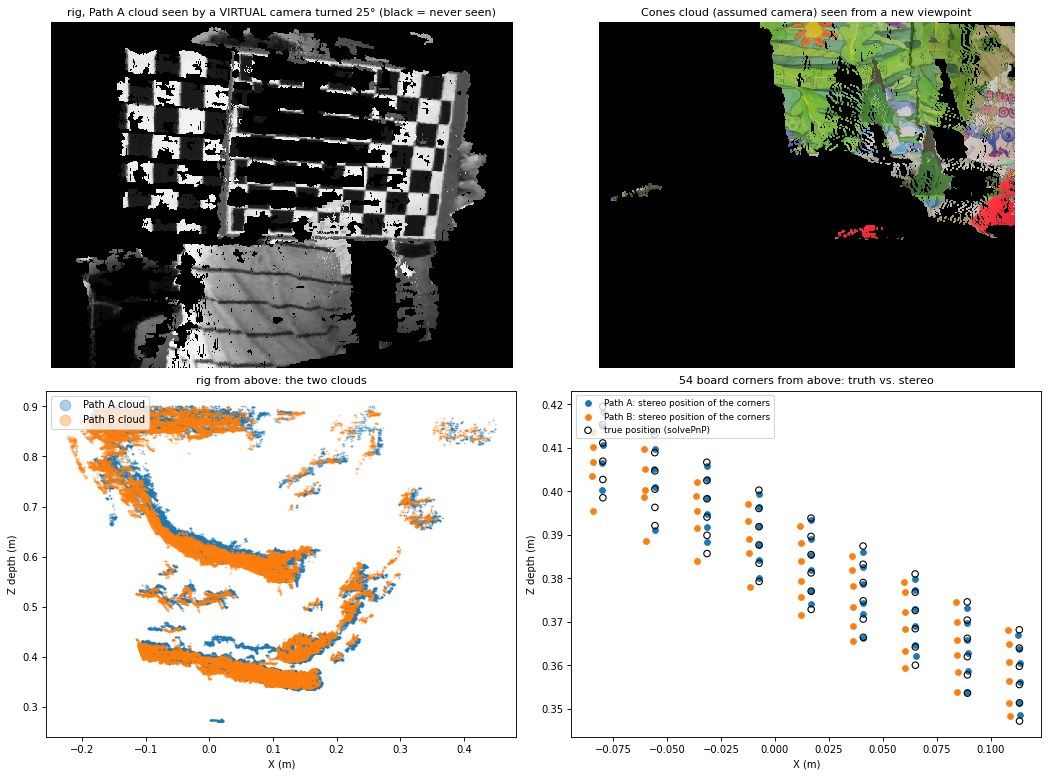

In [25]:
# --- 6.1 Back-projection, .ply export, novel view  [measured on the rig · assumed camera for Cones] -----
def backproject(disp: np.ndarray, colours: np.ndarray, f: float, cx: float, cy: float, baseline: float):
    """Lift every pixel with a valid disparity into 3D. Returns (N x 3 points in metres, N x 3 colours)."""
    v, u = np.nonzero(disp > 0)
    Z = f * baseline / disp[v, u]
    return np.column_stack([(u - cx) * Z / f, (v - cy) * Z / f, Z]), colours[v, u]


def save_ply(path, xyz: np.ndarray, rgb: np.ndarray) -> None:
    """Write an ASCII .ply file — opens in MeshLab, CloudCompare, Blender."""
    header = (
        "ply\nformat ascii 1.0\n"
        f"element vertex {len(xyz)}\n"
        "property float x\nproperty float y\nproperty float z\n"
        "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n"
    )
    with open(path, "w") as fh:
        fh.write(header)
        np.savetxt(fh, np.hstack([xyz, rgb]), fmt="%.4f %.4f %.4f %d %d %d")


def render_cloud(xyz, rgb, f, size, yaw_deg, pivot, shift=(0.0, 0.0, 0.0)) -> np.ndarray:
    """Photograph a coloured point cloud with a virtual pinhole camera that has moved: the scene is turned by `yaw_deg` about the
    vertical axis through `pivot` and shifted by `shift` (metres). Far points are painted first (painter's algorithm)."""
    pivot, shift = np.asarray(pivot, float), np.asarray(shift, float)
    c, s = np.cos(np.radians(yaw_deg)), np.sin(np.radians(yaw_deg))
    R = np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
    X = (xyz - pivot) @ R.T + pivot + shift
    z = X[:, 2]
    u = np.round(f * X[:, 0] / np.maximum(z, 1e-6) + size[0] / 2).astype(int)
    v = np.round(f * X[:, 1] / np.maximum(z, 1e-6) + size[1] / 2).astype(int)
    ok = (z > 0.05) & (u >= 0) & (u < size[0] - 1) & (v >= 0) & (v < size[1] - 1)
    order = np.argsort(-z[ok])
    u, v, colour = u[ok][order], v[ok][order], rgb[ok][order]
    image = np.zeros((size[1], size[0], 3), np.uint8)
    for du, dv in ((0, 0), (1, 0), (0, 1), (1, 1)):  # each point covers 2x2 pixels to close pinholes
        image[v + dv, u + du] = colour
    return image


# (a) Our desk rig, Path A and Path B: every number is measured → the cloud is in real metres.
def rig_cloud(rect: dict, m: dict):
    P1 = rect["P1"]
    return backproject(m["disp"], np.dstack([m["left"]] * 3), rect["f"], P1[0, 2], P1[1, 2], rect["baseline"])


cloud_A, col_A = rig_cloud(RECT_A, M_A)
cloud_B, col_B = rig_cloud(RECT_B, M_B)
xyz_cv = cv2.reprojectImageTo3D(M_A["disp"], RECT_A["Q"])[M_A["disp"] > 0]  # OpenCV's version of the same operation
print(
    f"our back-projection vs cv2.reprojectImageTo3D (Path A): max difference {np.abs(cloud_A - xyz_cv).max() * 1000:.3f} mm"
)
save_ply(OUT / "rig_pathA_cloud.ply", cloud_A, col_A)
save_ply(OUT / "rig_pathB_cloud.ply", cloud_B, col_B)

# (b) Middlebury Cones: its camera is not published → ASSUMED (Part 2.3), so the cloud's SCALE is assumed.
S = SCENE_DATA["cones"]
h_c, w_c = sg_c.shape
cloud_cones, col_cones = backproject(sg_c, S["left"], ASSUMED_F_PX, w_c / 2, h_c / 2, ASSUMED_B_M)
save_ply(OUT / "cones_pathA_cloud.ply", cloud_cones, col_cones)
print(
    f"rig  Path A: {len(cloud_A):,} points, Path B: {len(cloud_B):,} points  |  cones: {len(cloud_cones):,} points  → files in '{OUT}/'"
)


# 3D error of the 54 board corners: where stereo puts them vs. where the board really is
def corners_3d(rect: dict, m: dict) -> np.ndarray:
    P1 = rect["P1"]
    Z = m["z_est"]
    return np.vstack([(m["uv"][:, 0] - P1[0, 2]) * Z / rect["f"], (m["uv"][:, 1] - P1[1, 2]) * Z / rect["f"], Z])


err3d = {}
for name, rect, m in (("Path A", RECT_A, M_A), ("Path B", RECT_B, M_B)):
    est3 = corners_3d(rect, m)
    d3 = np.linalg.norm(est3 - m["xyz_ref"], axis=0)
    err3d[name] = (est3, d3)
    print(
        f"{name}: 3D error of the board corners — median {1000 * np.nanmedian(d3):.1f} mm, 90th percentile {1000 * np.nanpercentile(d3, 90):.1f} mm"
    )

novel_rig = render_cloud(
    cloud_A, col_A, RECT_A["f"], IMG_SIZE, yaw_deg=-25, pivot=(0, 0, S_A["z_mean"]), shift=(0.05, 0, 0)
)
novel_cones = render_cloud(
    cloud_cones, col_cones, ASSUMED_F_PX, (w_c, h_c), yaw_deg=-10, pivot=(0, 0, 6.0), shift=(0.5, 0, 0)
)

fig, axes = plt.subplots(2, 2, figsize=(13, 9.6), constrained_layout=True)
axes = axes.ravel()
axes[0].imshow(novel_rig)
axes[0].set_title("rig, Path A cloud seen by a VIRTUAL camera turned 25° (black = never seen)")
axes[0].axis("off")
axes[1].imshow(novel_cones)
axes[1].set_title("Cones cloud (assumed camera) seen from a new viewpoint")
axes[1].axis("off")
axes[2].scatter(
    cloud_A[cloud_A[:, 2] < 0.9, 0],
    cloud_A[cloud_A[:, 2] < 0.9, 2],
    s=0.4,
    color="tab:blue",
    alpha=0.35,
    label="Path A cloud",
)
axes[2].scatter(
    cloud_B[cloud_B[:, 2] < 0.9, 0],
    cloud_B[cloud_B[:, 2] < 0.9, 2],
    s=0.4,
    color="tab:orange",
    alpha=0.35,
    label="Path B cloud",
)
axes[2].set_xlabel("X (m)")
axes[2].set_ylabel("Z depth (m)")
axes[2].legend(markerscale=15, loc="upper left")
axes[2].set_title("rig from above: the two clouds")
for name, colour in (("Path A", "tab:blue"), ("Path B", "tab:orange")):
    est3, _ = err3d[name]
    axes[3].scatter(est3[0], est3[2], s=26, color=colour, label=f"{name}: stereo position of the corners")
axes[3].scatter(
    M_A["xyz_ref"][0], M_A["xyz_ref"][2], s=34, facecolors="none", edgecolors="k", label="true position (solvePnP)"
)
axes[3].set_xlabel("X (m)")
axes[3].set_ylabel("Z depth (m)")
axes[3].legend(loc="upper left", fontsize=8)
axes[3].set_title("54 board corners from above: truth vs. stereo")
plt.show()

---
# Part 7 — Guard rails, a reusable Path B function, submission checklist, README

*Needs:* Parts 0–6.

In [26]:
# --- 7.1 ⚠️ Cheap sanity checks against the silent errors of the brief's tips  [measured] ---------------
def stereo_sanity_check(focal_px: float, baseline_m: float, disparity: np.ndarray, image_width: int) -> list:
    """Cheap tests for the classic SILENT errors of a stereo pipeline. An empty list means nothing looks suspicious."""
    issues = []
    if not 0.01 <= baseline_m <= 2.0:
        issues.append(f"baseline {baseline_m:.3g} 'm' is not between 1 cm and 2 m — typed in mm or cm?")
    if not 0.3 <= focal_px / image_width <= 5.0:
        issues.append(f"focal length {focal_px:g} 'px' on a {image_width}-px image — typed in mm?")
    if float(np.nanmax(disparity)) > image_width:
        issues.append("disparity exceeds the image width — forgot to divide by 16?")
    if float(np.mean(disparity > 0)) < 0.2:
        issues.append(f"only {np.mean(disparity > 0):.0%} of pixels matched — check rectification and search range")
    return issues


disp_ok = M_A["disp"]
corner = np.round(M_A["uv"][27]).astype(int)  # one board corner
z_true = float(M_A["z_ref"][27])
cases = {
    "everything right": (RECT_A["f"], RECT_A["baseline"], disp_ok, 1.0),
    "baseline typed in millimetres": (RECT_A["f"], RECT_A["baseline"] * 1000, disp_ok, 1.0),
    "SGBM output not divided by 16": (RECT_A["f"], RECT_A["baseline"], disp_ok * 16, 1.0),
    "focal length entered in mm (4.0)": (4.0, RECT_A["baseline"], disp_ok, 1.0),
}
rows = []
for name, (f_px, base, disp, _) in cases.items():
    z = float(depth_from_disparity(disp[corner[1], corner[0]], f_px, base))
    issues = stereo_sanity_check(f_px, base, disp, IMG_SIZE[0])
    rows.append((name, f"{z:.4g} m", f"{100 * (z / z_true - 1):+.0f} %", issues[0] if issues else "OK"))
print(f"One board corner whose true depth is {z_true:.3f} m (from solvePnP):")
table(rows, ["what we got wrong", "reported depth", "vs truth", "what the guard says"])
print(
    "\nA wrong unit gives a plausible-looking but wrong depth. The only protection is a check against a KNOWN distance — here: the board."
)

One board corner whose true depth is 0.411 m (from solvePnP):
what we got wrong                 reported depth  vs truth  what the guard says                                               
--------------------------------  --------------  --------  ------------------------------------------------------------------
everything right                  0.4107 m        -0 %      OK                                                                
baseline typed in millimetres     410.7 m         +99791 %  baseline 83.7 'm' is not between 1 cm and 2 m — typed in mm or cm?
SGBM output not divided by 16     0.02567 m       -94 %     disparity exceeds the image width — forgot to divide by 16?       
focal length entered in mm (4.0)  0.003157 m      -99 %     focal length 4 'px' on a 640-px image — typed in mm?              

A wrong unit gives a plausible-looking but wrong depth. The only protection is a check against a KNOWN distance — here: the board.


In [27]:
# --- 7.2 A reusable Path B function, tested on the pair we walked through  [measured] --------------------
def path_b_reconstruct(gray_l, gray_r, K1, d1, K2, d2, baseline_m, num_disp, min_inliers=30):
    """The whole of Path B for ONE raw pair, given intrinsics from your own checkerboard calibration (Part 1.1) and the baseline length:
    SIFT → ratio test → RANSAC F → E → pose → refinement → rectification → SGBM → depth.
    Returns a dict with the rectified images, disparity, depth (m), the rectification model and diagnostics, or None if F cannot be estimated."""
    est = estimate_pose_B(*match_sift(gray_l, gray_r), K1, d1, K2, d2, refine=True)
    if not est["ok"] or est["n_inliers"] < min_inliers:
        return None
    rect = build_rectification(K1, d1, K2, d2, est["R"], est["t"] * baseline_m)
    rl, rr = rectify_images(rect, gray_l, gray_r)
    disp = run_sgbm(rl, rr, num_disp)
    depth = np.where(disp > 0, depth_from_disparity(np.maximum(disp, 1e-6), rect["f"], rect["baseline"]), np.nan)
    keep = est["inliers"]
    return {
        "rect": rect, "left": rl, "right": rr, "disp": disp, "depth": depth, "n_inliers": est["n_inliers"],
        "coverage": coverage(est["u_l"][keep]), "spread": disparity_spread(est["u_l"][keep], est["u_r"][keep]),
    }


res = path_b_reconstruct(GRAY_L[FOCUS], GRAY_R[FOCUS], K1, d1, K2, d2, BASELINE_RULER_M, NUM_DISP_RIG)
same = np.nanmedian(np.abs(res["depth"] - depth_map_B))
print(
    f"path_b_reconstruct on pair {PAIR_IDS[FOCUS]}: {res['n_inliers']} inliers, coverage {res['coverage']:.2f}, disparity spread {res['spread']:.0f} px"
)
print(
    f"median difference to the depth map of Part 4.5: {same:.4f} m (RANSAC is random; the refinement removes most of its scatter)"
)
print(
    "\nTo use it on YOUR data: calibrate with your own checkerboard photos (calibrate_mono), measure the baseline with a ruler, then"
)
print(
    "call path_b_reconstruct(gray_left, gray_right, K1, d1, K2, d2, baseline_m, num_disp) — and check coverage / spread (Part 5.2) first."
)

path_b_reconstruct on pair 01: 289 inliers, coverage 0.67, disparity spread 74 px
median difference to the depth map of Part 4.5: 0.0000 m (RANSAC is random; the refinement removes most of its scatter)

To use it on YOUR data: calibrate with your own checkerboard photos (calibrate_mono), measure the baseline with a ruler, then
call path_b_reconstruct(gray_left, gray_right, K1, d1, K2, d2, baseline_m, num_disp) — and check coverage / spread (Part 5.2) first.


In [28]:
# --- 7.3 Submission checklist — every number below was computed in this notebook  [measured] -------------
def pct_range(name: str) -> str:
    vals = [summary_of(f, name)["median_pct"] for f in FOLDS if summary_of(f, name)]
    return (
        f"median {np.median(vals):.2f} % ({len(vals)}/{N_PAIRS} pairs worked)" if vals else "never worked"
    )  # worked = see GROSS_ERR_PCT


sgbm_c = SCORES_A[("cones", "OpenCV StereoSGBM 5x5")]
sgbm_t = SCORES_A[("teddy", "OpenCV StereoSGBM 5x5")]
checklist = [
    (
        "Path A: disparity map and depth map, evaluated against ground truth",
        f"Cones: density {sgbm_c['density']:.0f} %, mean/median error {sgbm_c['mean']:.2f}/{sgbm_c['median']:.2f} px · "
        f"Teddy: {sgbm_t['density']:.0f} %, {sgbm_t['mean']:.2f}/{sgbm_t['median']:.2f} px",
    ),
    ("Path A: metric depth on a calibrated rig", f"leave-one-pair-out over 13 pairs: {pct_range('A')}"),
    (
        "Path B: camera calibration performed, intrinsics reported",
        f"fx = {K1[0, 0]:.1f} px, fy = {K1[1, 1]:.1f} px, RMS {CAL['rms'][0]:.2f} px; "
        f"differs from OpenCV's reference file by {f_dev:.3%} (Part 4.1)",
    ),
    (
        "Path B: F by detect-match-RANSAC, rectification applied",
        f"pair 01: {int(inl.sum())} inliers, row error {row_error(RECT_B, FOCUS).mean():.2f} px (Path A: {row_error(RECT_A, FOCUS).mean():.2f} px)",
    ),
    (
        "Path B: disparity and depth with the same method as Path A",
        f"SGBM, identical settings · all 13 pairs: {pct_range('B')}",
    ),
    ("Optional: point cloud", f"3 .ply files in '{OUT}/' (rig Path A, rig Path B, Cones)"),
    (
        "Quantitative A vs B comparison (real numbers)",
        f"Part 5.1: A {pct_range('A')}  |  B {pct_range('B')}  |  B with pooled matches {pct_range('B_pool')}",
    ),
    (
        "Written error attribution: calibration/rectification vs disparity estimation",
        "Parts 5.2–5.7 (diagnostics, injection experiments, matcher floor, error budget, written discussion)",
    ),
    ("Documented code and README", "Part 1 (typed functions) and the README below"),
]
for item, value in checklist:
    print(f"[x] {item}\n      → {value}")

[x] Path A: disparity map and depth map, evaluated against ground truth
      → Cones: density 83 %, mean/median error 0.65/0.19 px · Teddy: 81 %, 0.78/0.25 px
[x] Path A: metric depth on a calibrated rig
      → leave-one-pair-out over 13 pairs: median 0.17 % (13/13 pairs worked)
[x] Path B: camera calibration performed, intrinsics reported
      → fx = 535.7 px, fy = 535.6 px, RMS 0.42 px; differs from OpenCV's reference file by 0.029% (Part 4.1)
[x] Path B: F by detect-match-RANSAC, rectification applied
      → pair 01: 289 inliers, row error 0.16 px (Path A: 0.17 px)
[x] Path B: disparity and depth with the same method as Path A
      → SGBM, identical settings · all 13 pairs: median 1.23 % (7/13 pairs worked)
[x] Optional: point cloud
      → 3 .ply files in 'pp17_outputs/' (rig Path A, rig Path B, Cones)
[x] Quantitative A vs B comparison (real numbers)
      → Part 5.1: A median 0.17 % (13/13 pairs worked)  |  B median 1.23 % (7/13 pairs worked)  |  B with pooled matches median

---
# README — how to reproduce these results

**What this is.** A complete, measured worked solution to PP17 (*3D Reconstruction from Stereo Images*, Day 36): Path A, Path B,
a quantitative comparison with error attribution, an optional point cloud, and the written discussion (Part 5.7).

**Run it.**
1. Open `PP17_3DVision.ipynb` in Jupyter or Google Colab (CPU is enough; no GPU, no PyTorch).
2. Install the requirements if needed: `pip install opencv-python numpy matplotlib scipy` (OpenCV ≥ 4.4 for SIFT; tested with OpenCV 4.x **and** 5.x).
3. *Run all*. The first run downloads ≈ 2 MB of data into `pp17_data/` (pinned to the OpenCV 4.12.0 release tag). Everything runs in well under two minutes.

**What it creates.**
| Path | Content |
|---|---|
| `pp17_data/` | the downloaded photos and benchmark pairs (re-used on the next run) |
| `pp17_outputs/rig_pathA_cloud.ply`, `rig_pathB_cloud.ply` | point clouds of the desk rig (real metres) — open in MeshLab / CloudCompare / Blender |
| `pp17_outputs/cones_pathA_cloud.ply` | point cloud of the Middlebury *Cones* pair (**assumed** camera, so assumed scale) |

**Reproducibility.** One seed (`SEED = 17`) controls NumPy and OpenCV's RANSAC. Numbers can differ in the last digits between OpenCV versions
(floating-point and RANSAC details); the conclusions do not.

**Map of the notebook.**
| Part | Content | Rubric |
|---|---|---|
| 0 | setup, data | — |
| 1 | the pipeline as typed functions | code quality |
| 2 | Path A on Middlebury, scored against ground truth | Path A |
| 3 | Path A on the desk rig, metric depth | Path A |
| 4 | Path B, step by step | Path B |
| 5 | comparison, error attribution, written discussion | comparison |
| 6 | point cloud | optional |
| 7 | guard rails, reusable `path_b_reconstruct`, checklist, README | code quality |

**Using your own data.**
- *Path A:* replace the Middlebury pair in Part 2.1 by any rectified pair with ground-truth disparity (e.g. a KITTI subset) — keep the `score` function; report density with the error.
- *Path B:* photograph a checkerboard from **many different angles and distances** with the camera you use for the stereo pair (the brief's tip), measure the baseline with a ruler,
  fill `CORN_L`/`CORN_R` from your photos, set `PATTERN` and `SQUARE_M` (**in metres**), then call `path_b_reconstruct` (Part 7.2). Check `coverage` and `spread` before trusting the result.

**Honest limits** are listed in Part 5.7 (one rig, 13 pairs, baseline length from outside, assumed Middlebury camera).

---
### References and data credits
- Hartley, R., Zisserman, A. (2003). *Multiple View Geometry in Computer Vision*, 2nd ed. Cambridge University Press. — projection model, F and E matrices, Sampson error.
- Zhang, Z. (2000). A flexible new technique for camera calibration. *IEEE TPAMI* 22(11), 1330–1334.
- Lowe, D. G. (2004). Distinctive image features from scale-invariant keypoints. *IJCV* 60(2), 91–110.
- Fischler, M. A., Bolles, R. C. (1981). Random sample consensus. *Communications of the ACM* 24(6), 381–395.
- Sampson, P. D. (1982). Fitting conic sections to "very scattered" data. *Computer Graphics and Image Processing* 18(1), 97–108.
- Hirschmüller, H. (2008). Stereo processing by semiglobal matching and mutual information. *IEEE TPAMI* 30(2), 328–341.
- Scharstein, D., Szeliski, R. (2002). A taxonomy and evaluation of dense two-frame stereo correspondence algorithms. *IJCV* 47(1–3), 7–42.
- Scharstein, D., Szeliski, R. (2003). High-accuracy stereo depth maps using structured light. *CVPR 2003*.
- Day 36 notes, *3D Vision & Video Processing* (Gudsky Research Foundation, Research Intake 2026), §2–§5, §11 and the PP17 brief.

**Data.** Checkerboard stereo photos and `left_intrinsics.yml`: OpenCV `samples/data` (release 4.12.0). Middlebury *Cones* and *Teddy* (2003) with ground truth: OpenCV `opencv_extra`
`testdata/cv/stereomatching/datasets` (release 4.12.0), originally from the Middlebury stereo evaluation — please respect the original authors' terms when redistributing.